# Hybrid LSTM-XGBoost Portfolio Optimizer dengan XAI

**Sistem prediksi return saham menggunakan:**
- Hybrid LSTM + XGBoost untuk prediksi
- Feature engineering dari OHLCV data
- Explainable AI (XAI) untuk interpretasi
- Portfolio optimization dengan risk management

## Cell 1: Import Libraries

In [18]:
# Core libraries
import pandas as pd
import numpy as np
import warnings
from tabulate import tabulate

# Machine Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import xgboost as xgb

# Sklearn utilities
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error
from sklearn.covariance import LedoitWolf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# Statistical analysis
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy import stats

# Settings
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully")

All libraries imported successfully


## Cell 2: Hyperparameters & Configuration

In [19]:
# ===== DATA PARAMETERS =====
START_DATA = "2020-01-01"
END_DATA = "2025-11-30"
BACKTEST_START = "2020-01-02"
BACKTEST_STOP = "2025-11-30"

# ===== MODEL PARAMETERS =====
LSTM_LOOKBACK = 84
LSTM_EPOCHS = 30
RISK_FREE_RATE = 0.0475

# ===== TRADING LOGIC =====
REBAL_FREQ = "63B"  # Rebalance every ~3 months
PREDICTION_HORIZON = 21  # Predict 21-day forward return

# ===== STOCK SELECTION =====
PRED_FILTER = 0.02  # Min 2% predicted return
MIN_STOCKS = 6
MAX_STOCKS = 8

# ===== PORTFOLIO CONSTRAINTS =====
MAX_WEIGHT = 0.20  # Max 20% per stock
MAX_SEKTOR_WEIGHT = 0.30  # Max 30% per sector

# ===== RISK MANAGEMENT =====
STOP_WINDOW = 42  # Lookback for stop-loss calculation
STOP_MIN_CUT = 0.05  # Min 5% stop-loss
STOP_MAX_CUT = 0.12  # Max 12% stop-loss
STOP_MULTIPLIER = 4  # Volatility multiplier

# ===== TRANSACTION COSTS =====
BUY_FEE_RATE = 0.0020  # 0.2%
SELL_FEE_RATE = 0.0020  # 0.2%

print("Configuration loaded")
print(f" Backtest: {BACKTEST_START} - {BACKTEST_STOP}")
print(f" Rebalance: {REBAL_FREQ}")
print(f" Portfolio: {MIN_STOCKS}-{MAX_STOCKS} stocks")

Configuration loaded
 Backtest: 2020-01-02 - 2025-11-30
 Rebalance: 63B
 Portfolio: 6-8 stocks


## Cell 3: Stock Universe & Sector Mapping

In [20]:
# LQ45 Stock Universe
LQ45_TICKERS = [
    'ADRO.JK', 'AKRA.JK', 'AMMN.JK', 'AMRT.JK', 'ANTM.JK',
    'ASII.JK', 'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK',
    'BRPT.JK', 'CPIN.JK', 'CTRA.JK', 'EXCL.JK', 'GOTO.JK',
    'ICBP.JK', 'INCO.JK', 'INDF.JK', 'INTP.JK', 'ITMG.JK',
    'JPFA.JK', 'KLBF.JK', 'MDKA.JK', 'MEDC.JK', 'PGAS.JK',
    'PTBA.JK', 'SIDO.JK', 'SMGR.JK', 'TLKM.JK', 'UNTR.JK',
    'UNVR.JK', 'ESSA.JK', 'BBYB.JK', 'MIKA.JK', 'TOWR.JK',
    'HRUM.JK', 'INKP.JK', 'TKIM.JK', 'BUKA.JK', 'PWON.JK',
    'MAPA.JK', 'ERAA.JK', 'ELSA.JK', 'SMRA.JK', 'WSKT.JK'
]

# Sector Classification
SEKTOR_DICT = {
    'ADRO.JK': 'Energi', 'AKRA.JK': 'Energi', 'AMMN.JK': 'Pertambangan',
    'AMRT.JK': 'Konsumer', 'ANTM.JK': 'Pertambangan',
    'ASII.JK': 'Industri', 'BBCA.JK': 'Bank', 'BBNI.JK': 'Bank', 
    'BBRI.JK': 'Bank', 'BMRI.JK': 'Bank',
    'BRPT.JK': 'Industri', 'CPIN.JK': 'Konsumer', 'CTRA.JK': 'Properti', 
    'EXCL.JK': 'Telekom', 'GOTO.JK': 'Tech',
    'ICBP.JK': 'Konsumer', 'INCO.JK': 'Pertambangan', 'INDF.JK': 'Konsumer', 
    'INTP.JK': 'Industri', 'ITMG.JK': 'Energi',
    'JPFA.JK': 'Konsumer', 'KLBF.JK': 'Kesehatan', 'MDKA.JK': 'Pertambangan', 
    'MEDC.JK': 'Energi', 'PGAS.JK': 'Energi',
    'PTBA.JK': 'Energi', 'SIDO.JK': 'Kesehatan', 'SMGR.JK': 'Industri', 
    'TLKM.JK': 'Telekom', 'UNTR.JK': 'Industri',
    'UNVR.JK': 'Konsumer', 'ESSA.JK': 'Industri', 'BBYB.JK': 'Bank', 
    'MIKA.JK': 'Kesehatan', 'TOWR.JK': 'Infrastruktur',
    'HRUM.JK': 'Energi', 'INKP.JK': 'Industri', 'TKIM.JK': 'Industri', 
    'BUKA.JK': 'Tech', 'PWON.JK': 'Properti',
    'MAPA.JK': 'Retail', 'ERAA.JK': 'Retail', 'ELSA.JK': 'Energi', 
    'SMRA.JK': 'Properti', 'WSKT.JK': 'Konstruksi'
}

# Count stocks per sector
sector_counts = pd.Series(SEKTOR_DICT).value_counts()

print(f"Universe: {len(LQ45_TICKERS)} stocks")
print(f"\n Sector Distribution:")
for sector, count in sector_counts.items():
    print(f"  - {sector}: {count} stocks")

Universe: 45 stocks

 Sector Distribution:
  - Energi: 8 stocks
  - Industri: 8 stocks
  - Konsumer: 6 stocks
  - Bank: 5 stocks
  - Pertambangan: 4 stocks
  - Properti: 3 stocks
  - Kesehatan: 3 stocks
  - Telekom: 2 stocks
  - Tech: 2 stocks
  - Retail: 2 stocks
  - Infrastruktur: 1 stocks
  - Konstruksi: 1 stocks


## Cell 4: Data Loader Class

In [21]:
class LocalSingleFileDataProcessor:
    """Load and process OHLCV data from CSV"""
    
    def __init__(self, tickers, csv_path):
        self.tickers = tickers
        self.csv_path = csv_path
        self.data = None
        self.ohlcv = None
        self.close_prices = None
        self._missing_before = 0
    
    def load_data(self):
        """Load CSV with multi-level columns"""
        print(f" Loading: {self.csv_path}")
        try:
            df = pd.read_csv(self.csv_path, header=[0,1], index_col=0, parse_dates=True)
            # Clean ticker names (remove .JK suffix)
            df.columns = pd.MultiIndex.from_tuples([
                (lvl0, str(lvl1).replace(".JK", ""))
                for lvl0, lvl1 in df.columns
            ])
            self.data = df
            
            print("\nRAW DATA PREVIEW:")
            print(self.data.head())
            print(f"   Shape      : {self.data.shape}")
            print(f"   Date range : {self.data.index[0]} → {self.data.index[-1]}")
            print(f"   Columns    : {list(self.data.columns[:6])} ...")
            print(f"   Missing    : {self.data.isnull().sum().sum()} values\n")

            print(f" Loaded {len(df)} rows, {len(df.columns)} columns")
            return True
        except Exception as e:
            print(f" Failed: {e}")
            return False

    def extract_ohlcv(self):
        self._missing_before = self.data.isnull().sum().sum()  
        df = self.data.copy()                                  
        df = df.ffill()                             
        self.ohlcv = df
        return df
    
    def extract_close_prices(self):
        """Extract close prices"""
        if "Adj Close" in self.ohlcv.columns.get_level_values(0):
            close = self.ohlcv["Adj Close"]
        else:
            close = self.ohlcv["Close"]
        close = close.fillna(method="ffill")
        self.close_prices = close
        
        missing_after = self.ohlcv.isnull().sum().sum()
        print(f" CLEANING RESULT:")
        print(f"   Missing before : {self._missing_before}")
        print(f"   Missing after  : {missing_after}")
        print(f"   Filled         : {self._missing_before - missing_after} values")
        print(f"\n CLEANED DATA PREVIEW (OHLCV):")
        print(self.ohlcv.head())
        print(f"\n CLOSE PRICES PREVIEW:")
        print(self.close_prices.head())
        
        return close
    
    def get_benchmark(self, start_date, end_date):
        """Load IHSG benchmark"""
        print(" Loading IHSG benchmark")
        try:
            bm = pd.read_csv("IHSG.csv", header=[0, 1], index_col=0, parse_dates=True)
            if 'Adj Close' in bm.columns:
                price = bm['Adj Close']['^JKSE']
            elif 'Close' in bm.columns:
                price = bm['Close']['^JKSE']
            else:
                price = bm.iloc[:, 0]
            price = price.astype(float).sort_index()
            return price.loc[start_date:end_date]
        except Exception as e:
            print(f" Benchmark load failed: {e}")
            print("  Using average return fallback")
            idx = pd.date_range(start_date, end_date, freq="D")
            return pd.Series(np.cumprod(np.ones(len(idx)) * 1.0005), index=idx)

print("Data Loader class defined")

Data Loader class defined


## Cell 5: Feature Engineering Class

In [22]:
class EnhancedFeatureEngineer:
    """Create technical and price-based features"""
    
    def __init__(self, lookback_period=126):
        self.lookback_period = lookback_period
        self.ohlcv = None
        self._clip_bounds = None
    
    def _price_features(self, prices):
        """Calculate price-based features"""
        f = pd.DataFrame(index=prices.index)
        ret = prices.pct_change()
        
        # Momentum features
        for p in [5, 10, 21, 63]:
            f[f"momentum_{p}d"] = prices.pct_change(p)
        
        # Volatility
        f["volatility_21d"] = ret.rolling(21).std()
        f["vol_adj_mom"] = f["momentum_21d"] / (f["volatility_21d"] + 1e-10)
        
        # RSI
        delta = prices.diff()
        gain = delta.clip(lower=0).rolling(14).mean()
        loss = -delta.clip(upper=0).rolling(14).mean()
        rs = gain / (loss + 1e-10)
        f["rsi"] = 100 - (100 / (1 + rs))
        f["rsi_norm"] = (f["rsi"] - 50) / 50
        
        # Moving averages
        f["ma_20_50"] = prices.rolling(20).mean() / (prices.rolling(50).mean() + 1e-10)
        
        # Trend strength
        f["trend_strength"] = abs(f["momentum_21d"]) / (f["volatility_21d"] + 1e-10)
        
        # Price position
        f["price_vs_high"] = prices / (prices.rolling(63).max() + 1e-10)
        
        # Drawdown
        cummax = prices.expanding().max()
        f["drawdown"] = (prices - cummax) / (cummax + 1e-10)
        
        # Log return statistics
        logret = np.log(prices / prices.shift(1))
        f["logret_21_mean"] = logret.rolling(21).mean()
        f["logret_21_std"] = logret.rolling(21).std()
        
        return f
    
    def _ohlcv_features(self, stock, end_date):
        """Calculate OHLCV-based features (FIXED: volume ratio only)"""
        df = self.ohlcv.xs(stock, level=1, axis=1).loc[:end_date]
        price = df["Adj Close"] if "Adj Close" in df else df["Close"]
        
        f = pd.DataFrame(index=price.index)
        
        # Price range
        f["daily_range"] = (df["High"] - df["Low"]) / (price + 1e-10)
        
        price_scale = price.mean()  # skala harga saham itu sendiri
        f["body_ratio"] = abs(price - df["Open"]) / (df["High"] - df["Low"] + price_scale * 0.001).clip(lower=0.01)
        f["body_ratio"] = f["body_ratio"].clip(0, 1)
        
        # Volume ratio (FIXED: only ratio, no raw values)
        volume_sma = df["Volume"].rolling(20).mean()
        if len(volume_sma) > 0 and volume_sma.iloc[-1] > 0:
            volume_ratio = (df["Volume"].values / volume_sma.values)
            f["volume_ratio"] = pd.Series(volume_ratio, index=df.index)
        else:
            f["volume_ratio"] = pd.Series(1.0, index=df.index)
        
        # Log transform to reduce skew
        f["volume_ratio_log"] = np.log1p(f["volume_ratio"])
        
        return f
    
    def check_outliers(self, X):
        """Identifikasi fitur mana yang punya outlier ekstrim"""
        print("\n" + "="*80)
        print("🔍 OUTLIER ANALYSIS - SEBELUM CLEANING")
        print("="*80)
        
        for col in X.columns:
            q99 = X[col].quantile(0.99)
            q01 = X[col].quantile(0.01)
            max_val = X[col].max()
            min_val = X[col].min()
            
            # Cek outlier atas (terlalu tinggi)
            if max_val > q99 * 2:  # lebih dari 2x percentile 99
                print(f"⚠️  {col}: max {max_val:.2f} vs 99th {q99:.2f} ({(max_val/q99-1)*100:.1f}% lebih tinggi)")
            
            # Cek outlier bawah (terlalu rendah)
            if min_val < q01 * 2 and min_val < 0:
                print(f"⚠️  {col}: min {min_val:.2f} vs 1st {q01:.2f}")
        
        print("="*80)
    
    def _fit_clip_bounds(self, X, lower_q=0.01, upper_q=0.99):
        """Fit clip boundaries dari training data pertama — panggil sekali saja"""
        self._clip_bounds = {}
        for col in X.columns:
            self._clip_bounds[col] = (
                X[col].quantile(lower_q),
                X[col].quantile(upper_q)
            )

    def _clean_features(self, X):
        """Apply winsorize menggunakan bounds yang sudah di-fit"""
        if self._clip_bounds is None:
            raise ValueError("Panggil _fit_clip_bounds() dulu sebelum _clean_features()")
        X_clean = X.copy()
        for col in X_clean.columns:
            if col in self._clip_bounds:
                lo, hi = self._clip_bounds[col]
                X_clean[col] = X_clean[col].clip(lo, hi)
        return X_clean
    
    def create_dataset(self, close_df, as_of_date):
        """Create ML-ready dataset"""
        X_all, y_all = [], []
        future_ret = close_df.pct_change(PREDICTION_HORIZON).shift(-PREDICTION_HORIZON)
        
        for stock in close_df.columns:
            prices = close_df[stock][:as_of_date].dropna()
            if len(prices) < self.lookback_period:
                continue
            
            f_price = self._price_features(prices)
            f_ohlcv = self._ohlcv_features(stock, as_of_date)
            feats = pd.concat([f_price, f_ohlcv], axis=1)
            
            comb = pd.concat(
                [feats, future_ret[stock][:as_of_date].rename("target")],
                axis=1
            ).dropna()
            
            if len(comb) >= 227:
                X_all.append(comb.drop("target", axis=1))
                y_all.append(comb["target"])
        
        if X_all:
            X = pd.concat(X_all)
            y = pd.concat(y_all)

            self.check_outliers(X)

            # Fit hanya sekali di rebalancing pertama
            if self._clip_bounds is None:
                self._fit_clip_bounds(X)

            X = self._clean_features(X)
            return X, y
        return None, None
    
    # def create_dataset(self, close_df, as_of_date):
    #     """Create ML-ready dataset"""
    #     X_all, y_all = [], []
    #     future_ret = close_df.pct_change(PREDICTION_HORIZON).shift(-PREDICTION_HORIZON)
        
    #     for stock in close_df.columns:
    #         prices = close_df[stock][:as_of_date].dropna()
    #         if len(prices) < self.lookback_period:
    #             continue
            
    #         f_price = self._price_features(prices)
    #         f_ohlcv = self._ohlcv_features(stock, as_of_date)
    #         feats = pd.concat([f_price, f_ohlcv], axis=1)
            
    #         comb = pd.concat(
    #             [feats, future_ret[stock][:as_of_date].rename("target")],
    #             axis=1
    #         ).dropna()
            
    #         if len(comb) >= 227:
    #             X_all.append(comb.drop("target", axis=1))
    #             y_all.append(comb["target"])
        
    #     return (
    #         (pd.concat(X_all), pd.concat(y_all))
    #         if X_all else (None, None)
    #     )
    
    

    def print_feature_summary(self, X):
        """Print feature statistics table after engineering"""
        feature_meta = {
            "momentum_5d":     "Momentum (5 Hari)",
            "momentum_10d":    "Momentum (10 Hari)",
            "momentum_21d":    "Momentum (21 Hari)",
            "momentum_63d":    "Momentum (63 Hari)",
            "volatility_21d":  "Volatilitas Historis (21 Hari)",
            "vol_adj_mom":     "Risk-Adjusted Momentum",
            "rsi":             "Relative Strength Index (RSI)",
            "rsi_norm":        "RSI Ternormalisasi",
            "ma_20_50":        "Rasio MA20/MA50",
            "trend_strength":  "Indikator Kekuatan Tren",
            "price_vs_high":   "Harga vs High 63 Hari",
            "drawdown":        "Current Drawdown",
            "logret_21_mean":  "Rata-rata Log Return (21 Hari)",
            "logret_21_std":   "Standar Deviasi Log Return",
            "daily_range":     "Daily Trading Range",
            "body_ratio":      "Rasio Tubuh Candlestick",
            "volume_ratio":    "Rasio Volume Transaksi",
            "volume_ratio_log":"Log Rasio Volume",
        }

        desc = X.describe().T  # index = feature names
        rows = []
        for code, academic in feature_meta.items():
            if code in desc.index:
                rows.append({
                    "Nama Fitur (Code)":      code,
                    "Nama Fitur (Akademis)":  academic,
                    "Mean":                   f"{desc.loc[code, 'mean']:.6f}",
                    "Std. Dev":               f"{desc.loc[code, 'std']:.6f}",
                    "Min":                    f"{desc.loc[code, 'min']:.6f}",
                    "Max":                    f"{desc.loc[code, 'max']:.6f}",
                })

        summary_df = pd.DataFrame(rows)
        summary_df.index = range(1, len(summary_df) + 1)

        print("\n" + "="*85)
        print(" FEATURE ENGINEERING SUMMARY")
        print(f"   Total sampel : {len(X):,} baris")
        print(f"   Total fitur  : {len(X.columns)} kolom")
        print("="*85)
        print(summary_df.to_string())
        print("="*85 + "\n")

        
print("Feature Engineering class defined")

Feature Engineering class defined


## Cell 6: Hybrid LSTM-XGBoost Predictor

In [23]:
class ImprovedHybridPredictor:
    """Ensemble predictor combining LSTM and XGBoost"""
    
    def __init__(self, lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS):
        self.lookback = lookback
        self.lstm_epochs = lstm_epochs
        self.scaler = RobustScaler()
        self.lstm_model = None
        self.xgb_model = None
        self.feature_names = None
        self.lstm_weight = 0.5
        self.xgb_weight = 0.5
        self._X_lstm_val = None
        self._y_val = None
        self._X_xgb_val = None
        self.X_scaled_full = None
    
    def _build_lstm(self, input_shape):
        """Build LSTM architecture"""
        model = Sequential([
            LSTM(64, return_sequences=True, input_shape=input_shape),
            BatchNormalization(),
            LSTM(32),
            Dense(16, activation="relu"),
            Dropout(0.3),
            Dense(1)
        ])
        model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
        return model
    
    def train(self, X: pd.DataFrame, y: pd.Series, first_rebalance=False):
        """Train both LSTM and XGBoost models"""
        X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
        y = y.astype(float)
        self.feature_names = X.columns.tolist()
        
        # Scale features
        Xs = self.scaler.fit_transform(X)
        yv = y.values
        
        # Create sequences for LSTM
        X_lstm, y_lstm, X_xgb = [], [], []
        for i in range(self.lookback, len(Xs)):
            X_lstm.append(Xs[i - self.lookback:i])
            y_lstm.append(yv[i])
            X_xgb.append(Xs[i])
        
        X_lstm = np.array(X_lstm)
        y_lstm = np.array(y_lstm)
        X_xgb = np.array(X_xgb)
        
        if len(X_lstm) < 100:
            print("⚠️ Insufficient data for training")
            return False
        
        # Train/val split
        split = int(0.8 * len(X_lstm))
        
        # Train LSTM
        self.lstm_model = self._build_lstm((self.lookback, X_lstm.shape[2]))
        self.lstm_model.fit(
            X_lstm[:split], y_lstm[:split],
            validation_data=(X_lstm[split:], y_lstm[split:]),
            epochs=self.lstm_epochs,
            batch_size=32,
            callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
            verbose=0
        )
        
        # Train XGBoost
        self.xgb_model = xgb.XGBRegressor(
            n_estimators=300, max_depth=4, learning_rate=0.02,
            subsample=0.8, colsample_bytree=0.8, random_state=42
        )
        self.xgb_model.fit(X_xgb[:split], y_lstm[:split])
        
        # Calculate ensemble weights based on validation performance
        lstm_pred = self.lstm_model.predict(X_lstm[split:], verbose=0).flatten()
        xgb_pred = self.xgb_model.predict(X_xgb[split:])
        
        mse_lstm = mean_squared_error(y_lstm[split:], lstm_pred)
        mse_xgb = mean_squared_error(y_lstm[split:], xgb_pred)
        
        inv_lstm = 1 / (mse_lstm + 1e-9)
        inv_xgb = 1 / (mse_xgb + 1e-9)
        self.lstm_weight = inv_lstm / (inv_lstm + inv_xgb)
        self.xgb_weight = inv_xgb / (inv_lstm + inv_xgb)
        
        print(f" Val MSE: LSTM={mse_lstm:.6f} | XGB={mse_xgb:.6f}")
        print(f" Weights: LSTM={self.lstm_weight:.2f} | XGB={self.xgb_weight:.2f}")
        
        hybrid_pred = (
            self.lstm_weight * lstm_pred
            + self.xgb_weight * xgb_pred
        )

        mse_hybrid = mean_squared_error(y_lstm[split:], hybrid_pred)
        print(f" Hybrid MSE = {mse_hybrid:.6f}")
        
        # Store validation data for XAI
        self._X_lstm_val = X_lstm[split:]
        self._y_val = y_lstm[split:]
        self._X_xgb_val = X_xgb[split:]
        self.X_scaled_full = Xs
        
        return True
    
    def predict(self, X_latest: pd.DataFrame) -> np.ndarray:
        """Make predictions using ensemble"""
        X_latest = X_latest.fillna(0)
        Xs_latest = self.scaler.transform(X_latest)
        
        # XGBoost prediction
        xgb_pred = self.xgb_model.predict(Xs_latest)
        
        # LSTM prediction with historical context
        lstm_pred = []
        hist = self.X_scaled_full
        
        if len(hist) < self.lookback - 1:
            raise ValueError("Insufficient historical data for LSTM")
        
        for i in range(len(Xs_latest)):
            seq = np.vstack([
                hist[-(self.lookback - 1):],
                Xs_latest[i]
            ])
            seq = seq.reshape(1, self.lookback, -1)
            pred = self.lstm_model.predict(seq, verbose=0)[0][0]
            lstm_pred.append(pred)
        
        lstm_pred = np.array(lstm_pred)
        
        # Ensemble
        hybrid_pred = self.lstm_weight * lstm_pred + self.xgb_weight * xgb_pred
        return hybrid_pred

print("Hybrid Predictor class defined")

Hybrid Predictor class defined


## Cell 7: Stock-Specific XAI Engine

In [24]:
class StockSpecificXAI:
    """Explain individual stock selections"""
    
    def __init__(self):
        self.stock_explanations_history = []
    
    def explain_stock_selection(self, stock, features, prediction,
                                universe_features=None, universe_stats=None):
        """Generate explanation for a single stock"""
        feature_ranking = features.abs().sort_values(ascending=False)
        
        # Analyze all features
        all_features_analysis = {}
        for feat in features.index:
            feat_value = features[feat]
            all_features_analysis[feat] = {
                'value': feat_value,
                'abs_value': abs(feat_value),
                'percentile': 50
            }
            
            if universe_stats is not None and feat in universe_stats.columns:
                stats = universe_stats[feat]
                if stats['std'] > 0:
                    z_score = (feat_value - stats['mean']) / stats['std']
                    all_features_analysis[feat]['z_score'] = z_score
                    all_features_analysis[feat]['percentile'] = self._calculate_percentile(feat_value, stats)
        
        # Find extreme features
        extreme_features = {}
        for feat, analysis in all_features_analysis.items():
            if 'z_score' in analysis and abs(analysis['z_score']) > 1.5:
                extreme_features[feat] = analysis
        
        result = {
            'stock': stock,
            'prediction': prediction,
            'prediction_percent': prediction * 100,
            'top_features': {k: features[k] for k in feature_ranking.head(10).index},
            'all_features': all_features_analysis,
            'feature_values': features.to_dict(),
            'extreme_features': extreme_features,
            'category': self._categorize_stock(features),
            'explanation': self._generate_simple_explanation(
                stock, prediction, features, extreme_features, self._categorize_stock(features)
            )
        }
        return result
    
    def _categorize_stock(self, features):
        """Categorize stock based on features"""
        categories = []
        
        momentum_features = [f for f in features.index if 'momentum' in f]
        if momentum_features:
            avg_momentum = features[momentum_features].mean()
            if avg_momentum > 0.05:
                categories.append('High Momentum')
            elif avg_momentum < -0.05:
                categories.append('Negative Momentum')
        
        if 'price_vs_high' in features.index:
            if features['price_vs_high'] < 0.7:
                categories.append('Value Play')
            elif features['price_vs_high'] > 0.9:
                categories.append('Near High')
        
        if 'volatility_21d' in features.index and features['volatility_21d'] > 0.03:
            categories.append('High Volatility')
        
        if 'trend_strength' in features.index and features['trend_strength'] > 1.5:
            categories.append('Strong Trend')
        
        if 'volume_ratio' in features.index and features['volume_ratio'] > 1.5:
            categories.append('High Volume')
        
        return categories if categories else ['Neutral']
    
    def _generate_simple_explanation(self, stock, prediction, features,
                                      extreme_features, category):
        """Generate human-readable explanation"""
        explanation = f"{stock}: Prediksi return {prediction*100:.1f}%"
        
        if category:
            explanation += f" ({', '.join(category)})"
        
        sorted_features = features.abs().sort_values(ascending=False)
        top_3 = sorted_features.head(3).index
        
        if top_3.any():
            feat_names = [self._feature_to_english(f) for f in top_3]
            feat_values = [f"{features[f]:.3f}" for f in top_3]
            feat_str = ", ".join([f"{name}: {val}" for name, val in zip(feat_names, feat_values)])
            explanation += f". Faktor utama: {feat_str}"
        
        if extreme_features:
            extreme_list = []
            for feat, stats in list(extreme_features.items())[:2]:
                direction = "tinggi" if stats.get('z_score', 0) > 0 else "rendah"
                feat_name = self._feature_to_english(feat)
                extreme_list.append(f"{feat_name} {direction}")
            if extreme_list:
                explanation += f". Ekstrem: {', '.join(extreme_list)}"
        
        return explanation
    
    def _feature_to_english(self, feature_name):
        """Convert feature names to Indonesian"""
        mapping = {
            'momentum_5d': 'Momentum 5 hari', 'momentum_10d': 'Momentum 10 hari',
            'momentum_21d': 'Momentum 21 hari', 'momentum_63d': 'Momentum 63 hari',
            'volatility_21d': 'Volatilitas', 'vol_adj_mom': 'Momentum teradjust risiko',
            'rsi': 'RSI', 'rsi_norm': 'RSI normalized', 'ma_20_50': 'Rasio MA20/MA50',
            'trend_strength': 'Kekuatan trend', 'price_vs_high': 'Harga vs high 63 hari',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Return log 21 hari',
            'logret_21_std': 'Deviasi return', 'daily_range': 'Range harian',
            'body_ratio': 'Rasio body candle', 'volume_ratio': 'Rasio volume'
        }
        return mapping.get(feature_name, feature_name)
    
    def _calculate_percentile(self, value, stats):
        """Calculate percentile rank"""
        if stats['std'] == 0:
            return 50
        z = (value - stats['mean']) / stats['std']
        percentile = 50 + (z * 100 / 3)
        return max(0, min(100, percentile))

print("Stock-Specific XAI class defined")

Stock-Specific XAI class defined


## Cell 8: Rebalance XAI Engine

In [25]:
class RebalanceXAIEngine:
    """Analyze feature importance and explain portfolio decisions"""
    
    def __init__(self, max_local_samples=5):
        self.max_local_samples = max_local_samples
        self.stock_xai = StockSpecificXAI()
        self.xai_history = []
        self.feature_importance_history = []
    
    def get_hybrid_feature_importance(self, predictor):
        """Calculate feature importance from both models"""
        print("  Calculating Hybrid Feature Importance...")
        
        # XGBoost importance
        xgb_importance = predictor.xgb_model.feature_importances_
        
        # LSTM gradient-based importance
        lstm_importance = self._get_lstm_importance(predictor)
        
        # Normalize and combine
        xgb_norm = xgb_importance / (xgb_importance.sum() + 1e-10)
        lstm_norm = lstm_importance / (lstm_importance.sum() + 1e-10)
        
        hybrid_importance = (
            predictor.lstm_weight * lstm_norm +
            predictor.xgb_weight * xgb_norm
        )
        
        importance_series = pd.Series(
            hybrid_importance,
            index=predictor.feature_names[:len(hybrid_importance)]
        ).sort_values(ascending=False)
        
        return importance_series
    
    def _get_lstm_importance(self, predictor):
        """Calculate LSTM feature importance using gradients"""
        if predictor._X_lstm_val is None or len(predictor._X_lstm_val) == 0:
            return np.ones(len(predictor.feature_names)) / len(predictor.feature_names)
        
        n_samples = min(5, len(predictor._X_lstm_val))
        X_sample_lstm = predictor._X_lstm_val[:n_samples]
        
        importance_list = []
        for i in range(n_samples):
            seq = X_sample_lstm[i:i+1]
            seq_tensor = tf.convert_to_tensor(seq, dtype=tf.float32)
            
            with tf.GradientTape() as tape:
                tape.watch(seq_tensor)
                prediction = predictor.lstm_model(seq_tensor, training=False)
            
            gradients = tape.gradient(prediction, seq_tensor)
            sample_importance = tf.reduce_mean(tf.abs(gradients), axis=[0, 1]).numpy()
            importance_list.append(sample_importance)
        
        return np.mean(importance_list, axis=0)
    
    def run(self, predictor):
        """Run full XAI analysis"""
        print("\n RUNNING HYBRID FEATURE IMPORTANCE ANALYSIS")
        
        if (predictor.xgb_model is None or predictor.lstm_model is None or
            predictor.feature_names is None):
            print(" Models not trained yet")
            return {
                "global_hybrid": pd.Series(),
                "category_summary": []
            }
        
        try:
            hybrid_importance = self.get_hybrid_feature_importance(predictor)
            self.save_feature_importance_to_history(hybrid_importance, pd.Timestamp.now())
            
            # Display results
            print("\n" + "="*60)
            print(" HYBRID FEATURE IMPORTANCE (LSTM + XGBoost)")
            print("="*60)
            
            if not hybrid_importance.empty:
                print(f"\nModel weights - LSTM: {predictor.lstm_weight:.3f}, XGB: {predictor.xgb_weight:.3f}")
                
                # Top 15 features
                top_features = hybrid_importance.head(15)
                print("\n TOP 15 FEATURES:")
                print("-" * 50)
                for i, (feat, imp) in enumerate(top_features.items(), 1):
                    percentage = imp * 100
                    readable = self._get_readable_feature_name(feat)
                    print(f" {i:2d}. {readable:30s}: {imp:.6f} ({percentage:5.1f}%)")
                
                # Category summary
                category_summary = self.get_feature_category_summary(hybrid_importance)
                print("\n FEATURE CATEGORY ANALYSIS:")
                print("-" * 80)
                for cat_data in category_summary:
                    category = cat_data['category']
                    percentage = cat_data['percentage']
                    top_feats = ", ".join(cat_data['top_features'])
                    print(f" - {category:25s}: {percentage:.1f}% - {top_feats}")
                
                self._plot_feature_importance(hybrid_importance)
            
            return {
                "global_hybrid": hybrid_importance,
                "category_summary": category_summary if 'category_summary' in locals() else []
            }
        except Exception as e:
            print(f" Feature importance error: {e}")
            return {"global_hybrid": pd.Series(), "category_summary": []}
    
    def _get_readable_feature_name(self, feature_name):
        """Convert to readable format"""
        mapping = {
            'momentum_5d': 'Momentum 5D', 'momentum_10d': 'Momentum 10D',
            'momentum_21d': 'Momentum 21D', 'momentum_63d': 'Momentum 63D',
            'volatility_21d': 'Volatility 21D', 'vol_adj_mom': 'Risk-Adj Momentum',
            'rsi': 'RSI', 'rsi_norm': 'RSI Normalized', 'ma_20_50': 'MA20/MA50 Ratio',
            'trend_strength': 'Trend Strength', 'price_vs_high': 'Price vs 63D High',
            'drawdown': 'Drawdown', 'logret_21_mean': 'Log Return Mean',
            'logret_21_std': 'Log Return Std', 'daily_range': 'Daily Range',
            'body_ratio': 'Candle Body Ratio', 'volume_ratio': 'Volume Ratio'
        }
        return mapping.get(feature_name, feature_name[:25])
    
    def _plot_feature_importance(self, importance_series):
        """Visualize feature importance"""
        try:
            if importance_series.empty:
                return
            
            top_n = min(12, len(importance_series))
            top_features = importance_series.head(top_n)
            
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
            
            # Bar chart
            readable_names = [self._get_readable_feature_name(f) for f in top_features.index]
            bars = ax1.barh(range(len(top_features)), top_features.values)
            ax1.set_yticks(range(len(top_features)))
            ax1.set_yticklabels(readable_names, fontsize=9)
            ax1.set_xlabel('Importance Score')
            ax1.set_title(f'Top {top_n} Feature Importance', fontweight='bold')
            ax1.grid(True, alpha=0.3, axis='x')
            
            for bar, imp in zip(bars, top_features.values):
                bar.set_color('green' if imp > 0.05 else 'orange' if imp > 0.02 else 'red')
            
            # Pie chart for categories
            categories = {
                'Momentum Features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
                'Volatility Features': ['volatility_21d', 'vol_adj_mom'],
                'Technical Indicators': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
                'Price Action': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
                'Return Statistics': ['logret_21_mean', 'logret_21_std'],
                'Volume Features': ['volume_ratio', 'volume_ratio_log']
            }
            
            cat_data = {}
            for cat, feats in categories.items():
                valid_feats = [f for f in feats if f in importance_series.index]
                if valid_feats:
                    cat_data[cat] = importance_series[valid_feats].sum()
            
            if cat_data:
                cat_series = pd.Series(cat_data)
                colors = plt.cm.Set3(np.linspace(0, 1, len(cat_series)))
                ax2.pie(cat_series.values, labels=cat_series.index, autopct='%1.1f%%',
                       colors=colors, startangle=90)
                ax2.set_title('Importance by Category', fontweight='bold')
            
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f" Plot error: {e}")
    
    def explain_selected_stocks(self, selected_stocks, latest_features_df,
                               predictions, universe_features=None):
        """Generate stock-specific explanations"""
        print(f"\n STOCK-SPECIFIC EXPLANATIONS ({len(selected_stocks)} stocks)")
        
        universe_stats = None
        if universe_features is not None:
            universe_stats = self._calculate_universe_stats(universe_features)
        
        explanations = {}
        for stock in selected_stocks:
            if stock in latest_features_df.index:
                features = latest_features_df.loc[stock]
                prediction = predictions.get(stock, 0)
                
                explanation = self.stock_xai.explain_stock_selection(
                    stock=stock, features=features, prediction=prediction,
                    universe_stats=universe_stats
                )
                explanations[stock] = explanation
                print(f" - {explanation['explanation']}")
        
        self.xai_history.append({
            'rebalance_date': pd.Timestamp.now(),
            'selected_stocks': selected_stocks,
            'explanations': explanations
        })
        return explanations
    
    def _calculate_universe_stats(self, universe_features):
        """Calculate statistics across all stocks"""
        stats = {}
        for col in universe_features.columns:
            stats[col] = {
                'mean': universe_features[col].mean(),
                'std': universe_features[col].std(),
                'min': universe_features[col].min(),
                'max': universe_features[col].max(),
                'median': universe_features[col].median()
            }
        return pd.DataFrame(stats)
    
    def get_feature_category_summary(self, importance_series):
        """Summarize importance by feature category"""
        feature_categories = {
            'Momentum Features': {
                'features': ['momentum_5d', 'momentum_10d', 'momentum_21d', 'momentum_63d'],
            },
            'Volatility Features': {
                'features': ['volatility_21d', 'vol_adj_mom'],
            },
            'Technical Indicators': {
                'features': ['rsi', 'rsi_norm', 'ma_20_50', 'trend_strength'],
            },
            'Price Action': {
                'features': ['price_vs_high', 'drawdown', 'daily_range', 'body_ratio'],
            },
            'Return Statistics': {
                'features': ['logret_21_mean', 'logret_21_std'],
            },
            'Volume Features': {
                'features': ['volume_ratio', 'volume_ratio_log'],
            }
        }
        
        results = []
        for category, cat_info in feature_categories.items():
            valid_features = [f for f in cat_info['features'] if f in importance_series.index]
            if valid_features:
                cat_importance = importance_series[valid_features].sum()
                cat_percentage = cat_importance * 100
                top_features_in_cat = importance_series[valid_features].nlargest(2)
                top_feature_names = [self._get_readable_feature_name(f) for f in top_features_in_cat.index]
                
                results.append({
                    'category': category,
                    'percentage': cat_percentage,
                    'top_features': top_feature_names,
                    'feature_count': len(valid_features)
                })
        
        results.sort(key=lambda x: x['percentage'], reverse=True)
        return results
    
    def save_feature_importance_to_history(self, importance_series, rebalance_date):
        """Save for aggregate analysis"""
        if importance_series is not None and not importance_series.empty:
            self.feature_importance_history.append({
                'date': rebalance_date,
                'importance': importance_series.copy(),
                'top_features': importance_series.head(10).to_dict()
            })

print("Rebalance XAI Engine class defined")

Rebalance XAI Engine class defined


## Cell 9: Portfolio Optimizer

In [26]:
class EnhancedPortfolioOptimizer:
    """Optimize portfolio weights using Sharpe ratio maximization"""
    
    def __init__(self, risk_free_rate=RISK_FREE_RATE):
        self.risk_free_rate = risk_free_rate
    
    def optimize(self, expected_returns, cov_matrix):
        """Find optimal weights via SLSQP optimization"""
        n = len(expected_returns)
        mu = expected_returns.values if hasattr(expected_returns, 'values') else expected_returns
        
        # Apply shrinkage if covariance matrix is singular
        try:
            np.linalg.inv(cov_matrix)
        except np.linalg.LinAlgError:
            print("Singular covariance matrix, applying shrinkage")
            cov_matrix = LedoitWolf().fit(
                cov_matrix.values if isinstance(cov_matrix, pd.DataFrame) else cov_matrix
            ).covariance_
        
        def negative_sharpe(weights):
            port_return = np.sum(mu * weights)
            port_vol = np.sqrt(weights.T @ cov_matrix @ weights)
            sharpe = (port_return - self.risk_free_rate/252) / (port_vol + 1e-9)
            return -sharpe
        
        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
        bounds = [(0.01, MAX_WEIGHT) for _ in range(n)]
        init_weights = np.array([1/n] * n)
        
        result = minimize(
            negative_sharpe, init_weights, method='SLSQP',
            bounds=bounds, constraints=constraints,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        
        if result.success:
            weights = pd.Series(result.x, index=expected_returns.index)
            weights = weights[weights > 0.01]
            if len(weights) == 0:
                return self._risk_parity_fallback(expected_returns, cov_matrix)
            return weights / weights.sum()
        else:
            print("Optimization failed, using risk parity")
            return self._risk_parity_fallback(expected_returns, cov_matrix)
    
    def _risk_parity_fallback(self, expected_returns, cov_matrix):
        """Simple inverse volatility weighting"""
        vol = np.sqrt(np.diag(cov_matrix))
        weights = 1 / vol
        weights /= weights.sum()
        return pd.Series(weights, index=expected_returns.index)

print("Portfolio Optimizer class defined")

Portfolio Optimizer class defined


## Cell 10: Main Portfolio Recommender (Part 1/3)

In [27]:
class EnhancedPortfolioRecommender:
    """Main class orchestrating the entire system"""
    
    def __init__(self, tickers, start_date, end_date, risk_free_rate=RISK_FREE_RATE):
        self.processor = LocalSingleFileDataProcessor(tickers=tickers, csv_path="all_data.csv")
        self.feature_engineer = EnhancedFeatureEngineer(lookback_period=LSTM_LOOKBACK)
        self.predictor = ImprovedHybridPredictor(lookback=LSTM_LOOKBACK, lstm_epochs=LSTM_EPOCHS)
        self.optimizer = EnhancedPortfolioOptimizer(risk_free_rate=risk_free_rate)
        self.xai_engine = RebalanceXAIEngine(max_local_samples=5)
        
        self.all_stock_features_cache = {}
        self.close_prices = None
        self.ohlcv = None
        self.allocation_history = []
        self.previous_rec = None
    
    def setup(self):
        """Initialize data and features"""
        if not self.processor.load_data():
            return False
        self.ohlcv = self.processor.extract_ohlcv()
        if self.ohlcv is None:
            return False
        self.close_prices = self.processor.extract_close_prices()
        if self.close_prices is None:
            return False
        self.feature_engineer.ohlcv = self.ohlcv
        return True

print("Portfolio Recommender class defined (Part 1/3)")

Portfolio Recommender class defined (Part 1/3)


## Cell 11: Portfolio Recommender - Generate Recommendation (Part 2/3)

In [28]:
def generate_recommendation(self, as_of_date, first_rebalance=False):
    """Generate portfolio recommendation for a specific date"""
    print(f"\n{'='*60}")
    print(f"📅 REBALANCING: {as_of_date}")
    print(f"{'='*60}")
    
    # Create dataset
    X, y = self.feature_engineer.create_dataset(self.close_prices, as_of_date)
    if X is not None:
        self.feature_engineer.print_feature_summary(X)
        
    if X is None:
        print("Insufficient data")
        return self.previous_rec
    
    # Train models
    print("Training Hybrid Model...")
    success = self.predictor.train(X, y, first_rebalance=first_rebalance)
    if not success:
        print("Training failed")
        return self.previous_rec
    
    # Run XAI analysis
    print("\nRunning XAI Analysis...")
    xai_results = self.xai_engine.run(self.predictor)
    
    # Extract latest features
    print("\nExtracting latest features...")
    latest_features = {}
    for stock in self.close_prices.columns:
        prices = self.close_prices[stock].loc[:as_of_date].dropna()
        if len(prices) < 250:
            continue
        f_price = self.feature_engineer._price_features(prices)
        f_ohlcv = self.feature_engineer._ohlcv_features(stock, as_of_date)
        feats = pd.concat([f_price, f_ohlcv], axis=1) if f_ohlcv is not None else f_price
        latest_features[stock] = feats.iloc[-1]
    
    if not latest_features:
        print("No features extracted")
        return self.previous_rec
    
    latest_df = pd.DataFrame(latest_features).T
    
    # Make predictions
    print("\nMaking predictions...")
    preds = self.predictor.predict(latest_df)
    pred_series = pd.Series(preds, index=latest_df.index).sort_values(ascending=False)
    
    print(f"\nRaw predictions (top 15):")
    for i, (stock, score) in enumerate(pred_series.head(15).items(), 1):
        print(f" {i:2d}. {stock}: {score:.3%}")
    
    # Apply filters
    print(f"\nApplying filter (threshold={PRED_FILTER:.1%})...")
    positive = pred_series[pred_series > PRED_FILTER]
    
    if len(positive) < MIN_STOCKS:
        print(f" Only {len(positive)} above threshold, taking top {MIN_STOCKS}")
        positive = pred_series.nlargest(MIN_STOCKS)
    
    selected = positive.head(MAX_STOCKS)
    
    # Apply sector diversification
    selected = self._apply_sektor_diversification(selected)
    
    # Generate stock explanations
    if len(selected) > 0:
        universe_features = self._get_universe_features(as_of_date)
        stock_explanations = self.xai_engine.explain_selected_stocks(
            selected_stocks=selected.index.tolist(),
            latest_features_df=latest_df,
            predictions=selected.to_dict(),
            universe_features=universe_features
        )
    
    # Optimize portfolio
    print(f"\nPortfolio optimization...")
    if len(selected) < 2:
        weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
    else:
        try:
            hist_ret = self.close_prices[selected.index].pct_change().dropna()
            if len(hist_ret) < 60:
                weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
            else:
                weights = self.optimizer.optimize(selected, hist_ret.cov() * 252)
                weights = weights[weights > 0.01]
                if len(weights) == 0:
                    weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
        except Exception as e:
            print(f"Optimization error: {e}")
            weights = pd.Series([1/len(selected)] * len(selected), index=selected.index)
    
    weights = weights / weights.sum()
    
    # Create recommendation dataframe
    rec = pd.DataFrame({
        "Stock": weights.index,
        "Pred Return %": (selected[weights.index] * 100).round(2),
        "Weight %": (weights * 100).round(2)
    }).set_index("Stock")
    
    # Add technical indicators
    for stock in rec.index:
        if stock in latest_df.index:
            if 'price_vs_high' in latest_df.columns:
                rec.loc[stock, "Price vs High"] = f"{latest_df.loc[stock, 'price_vs_high']:.1%}"
            if 'volatility_21d' in latest_df.columns:
                rec.loc[stock, "Volatility 21d"] = f"{latest_df.loc[stock, 'volatility_21d']:.2%}"
    
    print("\n" + "="*60)
    print("FINAL PORTFOLIO RECOMMENDATION")
    print("="*60)
    print(tabulate(rec, headers="keys", tablefmt="psql", floatfmt=".2f"))
    
    self.previous_rec = rec
    return rec

# Attach method to class
EnhancedPortfolioRecommender.generate_recommendation = generate_recommendation

print("Generate recommendation method added (Part 2/3)")

Generate recommendation method added (Part 2/3)


## Cell 12: Portfolio Recommender - Helper Methods & Backtest (Part 3/3)

In [29]:
def _apply_sektor_diversification(self, selected):
    """Apply sector diversification rules"""
    print(f"\nSECTOR DIVERSIFICATION:")
    selected_copy = selected.copy()
    
    sektor_alloc = {}
    for stock in selected_copy.index:
        clean_stock = stock.replace(".JK", "")
        sektor = SEKTOR_DICT.get(stock) or SEKTOR_DICT.get(clean_stock) or SEKTOR_DICT.get(f"{clean_stock}.JK")
        if sektor is None:
            sektor = 'Lainnya'
        sektor_alloc.setdefault(sektor, []).append(stock)
    
    # Enforce 30% rule
    for sektor, stocks in sektor_alloc.items():
        if len(stocks) / len(selected) > MAX_SEKTOR_WEIGHT:
            print(f"Sector {sektor} >{MAX_SEKTOR_WEIGHT*100:.0f}% ({len(stocks)}/{len(selected)})")
            max_allowed = int(len(selected) * MAX_SEKTOR_WEIGHT)
            to_drop = len(stocks) - max_allowed
            if to_drop > 0:
                low_pred = selected_copy[stocks].nsmallest(to_drop)
                selected_copy = selected_copy.drop(low_pred.index)
    
    return selected if len(selected_copy) < 3 else selected_copy

def _get_universe_features(self, as_of_date):
    """Get features for all stocks (with caching)"""
    if as_of_date in self.all_stock_features_cache:
        return self.all_stock_features_cache[as_of_date]
    
    all_features = {}
    for stock in self.close_prices.columns:
        prices = self.close_prices[stock].loc[:as_of_date].dropna()
        if len(prices) < 250:
            continue
        f_price = self.feature_engineer._price_features(prices)
        f_ohlcv = self.feature_engineer._ohlcv_features(stock, as_of_date)
        feats = pd.concat([f_price, f_ohlcv], axis=1) if f_ohlcv is not None else f_price
        if len(feats) > 0:
            all_features[stock] = feats.iloc[-1]
    
    if all_features:
        df = pd.DataFrame(all_features).T
        self.all_stock_features_cache[as_of_date] = df
        return df
    return None

# Attach helper methods
EnhancedPortfolioRecommender._apply_sektor_diversification = _apply_sektor_diversification
EnhancedPortfolioRecommender._get_universe_features = _get_universe_features

print("Helper methods added (Part 3/3)")
print("EnhancedPortfolioRecommender class complete!")

Helper methods added (Part 3/3)
EnhancedPortfolioRecommender class complete!


## Cell 13: Backtest Engine

In [30]:
def run_backtest(self, start_date, end_date, freq=REBAL_FREQ):
    """Run full portfolio backtest with rebalancing"""
    print(f"\n{'='*60}")
    print(f"BACKTEST: {start_date} → {end_date}")
    print(f"{'='*60}")
    
    cash = 100_000_000
    self.cash_initial = cash
    holdings = {}
    holdings_meta = {}
    portfolio_value = []
    dates = []
    self.allocation_history = []
    
    current_date = pd.to_datetime(start_date)
    rebalance_dates = pd.date_range(start=start_date, end=end_date, freq=freq)
    end_date = pd.to_datetime(end_date)
    
    for date in self.close_prices.index:
        if date < current_date or date > end_date:
            continue
        
        is_rebalance = date in rebalance_dates
        
        # Rebalance portfolio
        if is_rebalance:
            rec = self.generate_recommendation(
                date.strftime("%Y-%m-%d"),
                first_rebalance=(len(self.allocation_history) == 0)
            )
            
            if rec is not None:
                # Sell all
                for s, q in holdings.items():
                    cash += q * self.close_prices.loc[date, s] * (1 - SELL_FEE_RATE)
                holdings.clear()
                holdings_meta.clear()
                
                # Buy new
                total_val = cash
                for s, row in rec.iterrows():
                    w = row["Weight %"] / 100
                    price = self.close_prices.loc[date, s]
                    qty = int((total_val * w) / (price * (1 + BUY_FEE_RATE)))
                    if qty > 0:
                        holdings[s] = qty
                        cash -= qty * price * (1 + BUY_FEE_RATE)
                        
                        # Set stop-loss
                        past = self.close_prices[s].loc[:date].tail(STOP_WINDOW)
                        vol = past.pct_change().std()
                        vol = 0.02 if pd.isna(vol) or vol == 0 else vol
                        cut = np.clip(STOP_MULTIPLIER * vol, STOP_MIN_CUT, STOP_MAX_CUT)
                        holdings_meta[s] = {
                            "stop_price": price * (1 - cut),
                            "buy_price": price,
                            "high_price": price,
                            "vol": vol
                        }
        
        # Update trailing stops
        for s in list(holdings.keys()):
            price = self.close_prices.loc[date, s]
            meta = holdings_meta[s]
            if price > meta['high_price']:
                meta['high_price'] = price
                meta['stop_price'] = price * (1 - np.clip(
                    STOP_MULTIPLIER * meta['vol'], STOP_MIN_CUT, STOP_MAX_CUT
                ))
        
        # Check stop-losses
        to_sell = []
        for s, q in holdings.items():
            price = self.close_prices.loc[date, s]
            if price < holdings_meta[s]["stop_price"]:
                print(f"STOP-LOSS {s} @ {price:,.0f}")
                cash += q * price * (1 - SELL_FEE_RATE)
                to_sell.append(s)
        
        for s in to_sell:
            del holdings[s]
            del holdings_meta[s]
        
        # Record portfolio value
        stock_val = sum(q * self.close_prices.loc[date, s] for s, q in holdings.items())
        total_val = stock_val + cash
        portfolio_value.append(total_val)
        dates.append(date)
    
    self._print_metrics_and_plot(portfolio_value, dates)
    return pd.Series(portfolio_value, index=dates)

# Attach backtest method
EnhancedPortfolioRecommender.run_backtest = run_backtest

print("Backtest engine added")

Backtest engine added


## Cell 14: Performance Metrics & Visualization

In [31]:
def _print_metrics_and_plot(self, portfolio_value, dates):
    """Calculate and display performance metrics"""
    pf = pd.Series(portfolio_value, index=dates)
    ret = pf.pct_change().dropna()
    bm = self.processor.get_benchmark(dates[0], dates[-1])
    bm_ret = bm.pct_change().dropna()
    
    # Calculate metrics
    total_ret = pf.iloc[-1] / pf.iloc[0] - 1
    bm_total_ret = bm.iloc[-1] / bm.iloc[0] - 1
    
    days = (pf.index[-1] - pf.index[0]).days
    if days <= 0:
        print("\nBacktest duration too short")
        return
    
    ann_ret = (1 + total_ret) ** (365 / days) - 1
    bm_ann_ret = (1 + bm_total_ret) ** (365 / days) - 1
    vol = ret.std() * np.sqrt(252)
    bm_vol = bm_ret.std() * np.sqrt(252)
    
    sharpe = (ann_ret - RISK_FREE_RATE) / (vol + 1e-9)
    bm_sharpe = (bm_ann_ret - RISK_FREE_RATE) / (bm_vol + 1e-9)
    
    cummax = pf.expanding().max()
    dd = (pf - cummax) / cummax
    max_dd = dd.min()
    
    bm_cummax = bm.expanding().max()
    bm_dd = (bm - bm_cummax) / bm_cummax
    bm_max_dd = bm_dd.min()
    
    # Alpha and Beta
    aligned = pd.concat([ret, bm_ret], axis=1).dropna()
    aligned.columns = ["Port", "Bench"]
    X = sm.add_constant(aligned["Bench"])
    model = sm.OLS(aligned["Port"], X).fit()
    alpha, beta = model.params.iloc[0] * 252, model.params.iloc[1]
    
    # Print results
    print("\n" + "=" * 80)
    print("FINAL BACKTEST RESULTS vs IHSG")
    print("=" * 80)
    print(f"{'METRIC':<25} {'STRATEGY':>15} {'IHSG':>15} {'DIFF':>15}")
    print("-" * 80)
    print(f"{'Total Return':<25} {total_ret*100:>14.2f}% {bm_total_ret*100:>14.2f}% {(total_ret - bm_total_ret)*100:>14.2f}%")
    print(f"{'Annual Return':<25} {ann_ret*100:>14.2f}% {bm_ann_ret*100:>14.2f}% {(ann_ret - bm_ann_ret)*100:>14.2f}%")
    print(f"{'Volatility':<25} {vol*100:>14.2f}% {bm_vol*100:>14.2f}% {(vol - bm_vol)*100:>14.2f}%")
    print(f"{'Sharpe Ratio':<25} {sharpe:>15.2f} {bm_sharpe:>15.2f} {(sharpe - bm_sharpe):>15.2f}")
    print(f"{'Max Drawdown':<25} {max_dd*100:>14.2f}% {bm_max_dd*100:>14.2f}% {(max_dd - bm_max_dd)*100:>14.2f}%")
    print(f"{'Alpha (vs IHSG)':<25} {alpha*100:>14.2f}%")
    print(f"{'Beta (vs IHSG)':<25} {beta:>15.2f}")
    print("=" * 80)
    
    # Visualization
    fig = plt.figure(figsize=(20, 12))
    gs = gridspec.GridSpec(2, 2)
    
    # Equity curve
    ax1 = plt.subplot(gs[0, :])
    ax1.plot(pf / pf.iloc[0] * 100, label=f"Strategy ({total_ret*100:.1f}%)", linewidth=2.5)
    ax1.plot(bm / bm.iloc[0] * 100, "--", label=f"IHSG ({bm_total_ret*100:.1f}%)", linewidth=2)
    ax1.legend(fontsize=12)
    ax1.set_title(f"Equity Curve (Outperformance: {(total_ret - bm_total_ret)*100:.1f}%)",
                  fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # Drawdown
    ax2 = plt.subplot(gs[1, 0])
    ax2.fill_between(dd.index, dd.values * 100, 0, color='red', alpha=0.4,
                     label=f"Strategy ({max_dd*100:.1f}%)")
    ax2.fill_between(bm_dd.index, bm_dd.values * 100, 0, color='orange', alpha=0.3,
                     label=f"IHSG ({bm_max_dd*100:.1f}%)")
    ax2.legend()
    ax2.set_title("Drawdown Comparison", fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # Rolling Sharpe
    ax3 = plt.subplot(gs[1, 1])
    rolling_window = min(126, len(ret))
    if rolling_window > 20:
        rolling_sharpe = (ret.rolling(rolling_window).mean() / 
                         ret.rolling(rolling_window).std()) * np.sqrt(252)
        ax3.plot(rolling_sharpe, label=f"Strategy ({sharpe:.2f})")
        ax3.axhline(y=0, color='black', linestyle='--', alpha=0.5)
        ax3.legend()
        ax3.set_title(f"Rolling Sharpe ({rolling_window}d)", fontweight='bold')
        ax3.grid(True, alpha=0.3)
    
    plt.suptitle("📊 BACKTEST PERFORMANCE ANALYSIS", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Attach method
EnhancedPortfolioRecommender._print_metrics_and_plot = _print_metrics_and_plot

print("Performance metrics & visualization added")

Performance metrics & visualization added


## Cell 15: XAI Summary Report

In [32]:
def print_xai_summary(self):
    """Print comprehensive XAI summary across all rebalances"""
    if not hasattr(self.xai_engine, 'xai_history') or not self.xai_engine.xai_history:
        print("No XAI history available")
        return
    
    print("\n" + "="*60)
    print("XAI SUMMARY ACROSS REBALANCES")
    print("="*60)
    
    # Collect data
    all_categories = []
    all_extreme_features = []
    all_feature_importance = []
    
    for rebalance in self.xai_engine.xai_history:
        if 'explanations' in rebalance:
            for stock, explanation in rebalance['explanations'].items():
                all_categories.extend(explanation['category'])
                for feat in explanation.get('extreme_features', {}):
                    all_extreme_features.append(feat)
    
    if hasattr(self.xai_engine, 'feature_importance_history'):
        for imp_data in self.xai_engine.feature_importance_history:
            if 'importance' in imp_data and not imp_data['importance'].empty:
                all_feature_importance.append(imp_data['importance'])
    
    # Feature category analysis
    if all_feature_importance:
        avg_importance = pd.concat(all_feature_importance, axis=1).mean(axis=1)
        avg_importance = avg_importance.sort_values(ascending=False)
        category_summary = self.xai_engine.get_feature_category_summary(avg_importance)
        
        print("\nFEATURE CATEGORY ANALYSIS (AVERAGE):")
        print("-" * 90)
        print(f"{'Category':<25} {'Contribution (%)':<25} {'Top Indicators'}")
        print("-" * 90)
        
        total_percentage = sum(cat['percentage'] for cat in category_summary)
        for cat_data in category_summary:
            category = cat_data['category']
            raw_percentage = cat_data['percentage']
            normalized_percentage = (raw_percentage / total_percentage * 100) if total_percentage > 0 else raw_percentage
            top_features = ", ".join(cat_data['top_features'])
            percentage_str = f"{normalized_percentage:.1f}%"
            print(f"{category:<25} {percentage_str:<25} {top_features}")
    
    # Stock categories
    if all_categories:
        print("\nMOST COMMON STOCK CATEGORIES:")
        cat_counts = pd.Series(all_categories).value_counts()
        for cat, count in cat_counts.head(5).items():
            percentage = (count / len(all_categories)) * 100
            print(f" - {cat}: {count} selections ({percentage:.1f}%)")
    
    # Extreme features
    if all_extreme_features:
        print("\nMOST FREQUENT EXTREME FEATURES:")
        feat_counts = pd.Series(all_extreme_features).value_counts()
        for feat, count in feat_counts.head(5).items():
            readable = self.xai_engine._get_readable_feature_name(feat)
            percentage = (count / len(self.xai_engine.xai_history)) * 100
            print(f" - {readable}: {count} occurrences ({percentage:.1f}% of rebalances)")
    
    print("\n" + "="*60)

# Attach method
EnhancedPortfolioRecommender.print_xai_summary = print_xai_summary

print("XAI summary report added")

XAI summary report added


## Cell 16: Initialize and Run System

In [33]:
# Initialize system
print("\n" + "="*60)
print("HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER")
print("="*60)

recommender = EnhancedPortfolioRecommender(
    tickers=LQ45_TICKERS,
    start_date=START_DATA,
    end_date=END_DATA,
    risk_free_rate=RISK_FREE_RATE
)

# Setup data
print("\nLoading data...")
if not recommender.setup():
    print("SETUP FAILED")
    raise Exception("Data loading failed")

print("System initialized successfully!")
print(f"\nReady to backtest: {BACKTEST_START} → {BACKTEST_STOP}")
print(f"Rebalance frequency: {REBAL_FREQ}")
print(f"Portfolio size: {MIN_STOCKS}-{MAX_STOCKS} stocks")


HYBRID LSTM-XGBOOST PORTFOLIO OPTIMIZER

Loading data...
 Loading: all_data.csv

RAW DATA PREVIEW:
             Adj Close                                                        \
                  ADRO        AKRA AMMN        AMRT        ANTM         ASII   
Date                                                                           
2017-01-02  422.978394  744.446838  NaN  569.011658  721.587830  5174.230469   
2017-01-03  434.207947  722.733643  NaN  564.459534  713.525391  5127.333008   
2017-01-04  424.226074  735.141235  NaN  528.042786  697.400513  5002.276855   
2017-01-05  415.492035  725.835571  NaN  528.042786  701.431763  5080.437500   
2017-01-06  422.978394  732.039307  NaN  537.146912  697.400513  5111.701660   

                                                               ...  \
                   BBCA         BBNI         BBRI        BBYB  ...   
Date                                                           ...   
2017-01-02  2588.967773  2018.848633  1369.781738

## Cell 17: Run Full Backtest


STARTING BACKTEST

BACKTEST: 2020-01-02 → 2025-11-30

📅 REBALANCING: 2020-01-02

🔍 OUTLIER ANALYSIS - SEBELUM CLEANING
⚠️  momentum_5d: max 3.87 vs 99th 0.18 (2032.9% lebih tinggi)
⚠️  momentum_5d: min -0.82 vs 1st -0.13
⚠️  momentum_10d: max 3.83 vs 99th 0.27 (1345.0% lebih tinggi)
⚠️  momentum_10d: min -0.82 vs 1st -0.18
⚠️  momentum_21d: max 3.67 vs 99th 0.43 (751.6% lebih tinggi)
⚠️  momentum_21d: min -0.82 vs 1st -0.23
⚠️  momentum_63d: max 3.54 vs 99th 1.05 (237.4% lebih tinggi)
⚠️  momentum_63d: min -0.84 vs 1st -0.34
⚠️  volatility_21d: max 1.24 vs 99th 0.06 (1996.4% lebih tinggi)
⚠️  logret_21_mean: max 0.07 vs 99th 0.02 (329.9% lebih tinggi)
⚠️  logret_21_mean: min -0.08 vs 1st -0.01
⚠️  logret_21_std: max 0.72 vs 99th 0.06 (1191.6% lebih tinggi)
⚠️  daily_range: max 0.66 vs 99th 0.18 (272.4% lebih tinggi)
⚠️  volume_ratio: max 19.23 vs 99th 4.57 (320.9% lebih tinggi)

 FEATURE ENGINEERING SUMMARY
   Total sampel : 29,475 baris
   Total fitur  : 18 kolom
   Nama Fitur (Code)

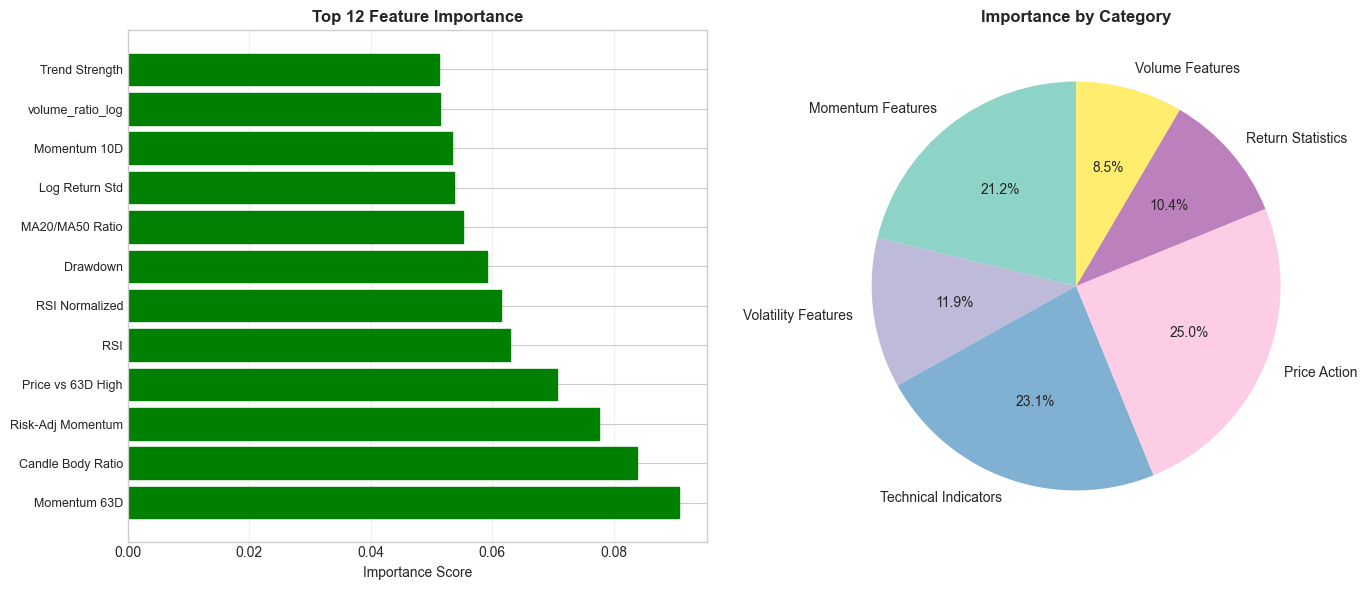


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. TOWR: 2.381%
  2. BBCA: 2.093%
  3. BBRI: 2.046%
  4. BMRI: 1.994%
  5. INCO: 1.914%
  6. INDF: 1.399%
  7. AKRA: 1.365%
  8. HRUM: 1.349%
  9. BBNI: 1.343%
 10. ASII: 1.309%
 11. KLBF: 1.237%
 12. SIDO: 1.203%
 13. WSKT: 1.160%
 14. PGAS: 1.085%
 15. PTBA: 0.979%

Applying filter (threshold=2.0%)...
 Only 3 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Bank >30% (3/6)

 STOCK-SPECIFIC EXPLANATIONS (4 stocks)
 - TOWR: Prediksi return 2.4% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 79.364, Kekuatan trend: 8.103, Momentum teradjust risiko: 8.103. Ekstrem: Momentum 10 hari tinggi, Momentum 63 hari tinggi
 - BBCA: Prediksi return 2.1% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 69.281, Kekuatan trend: 5.790, Momentum teradjust risiko: 5.790
 - INCO: Prediksi return 1.9% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 73.469, Kekuatan trend: 9

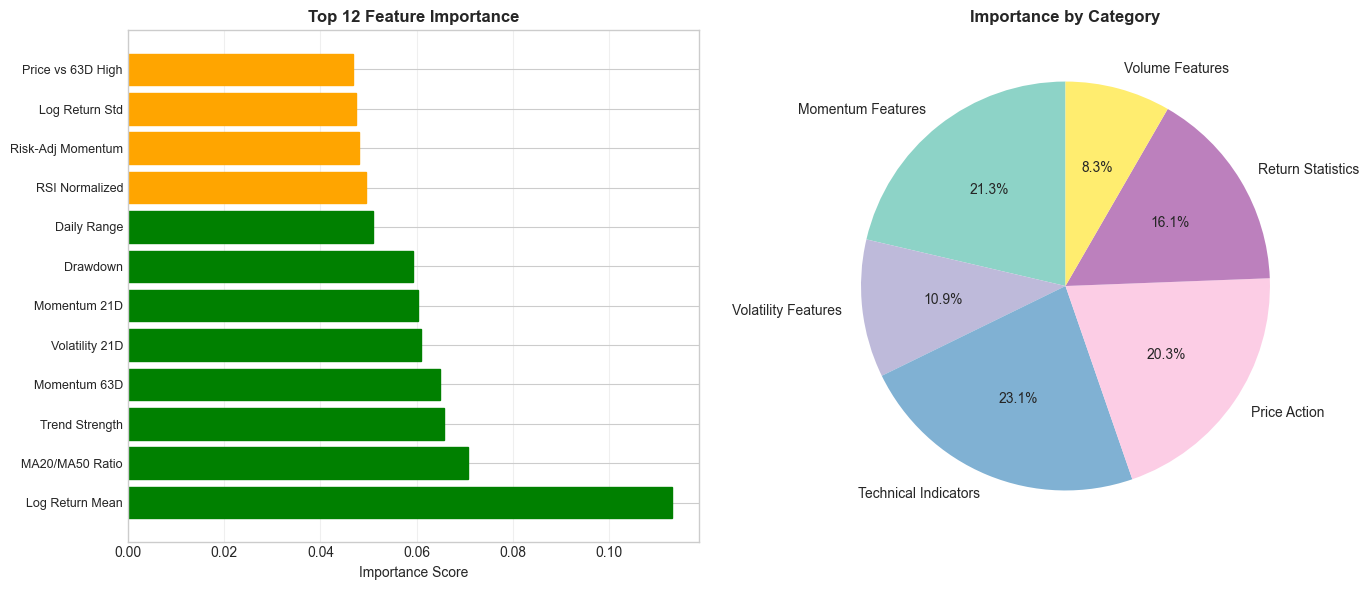


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. SMRA: 27.477%
  2. CTRA: 21.486%
  3. BRPT: 19.706%
  4. AKRA: 17.120%
  5. ADRO: 15.350%
  6. EXCL: 15.340%
  7. INCO: 14.558%
  8. MAPA: 14.445%
  9. INKP: 14.015%
 10. TKIM: 13.869%
 11. WSKT: 13.627%
 12. PGAS: 13.509%
 13. ANTM: 13.032%
 14. ERAA: 12.667%
 15. JPFA: 12.524%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:

 STOCK-SPECIFIC EXPLANATIONS (8 stocks)
 - SMRA: Prediksi return 27.5% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 12.821, Kekuatan trend: 10.838, Momentum teradjust risiko: -10.838. Ekstrem: Momentum 5 hari rendah, Momentum 10 hari rendah
 - CTRA: Prediksi return 21.5% (Negative Momentum, Value Play, High Volatility, Strong Trend, High Volume). Faktor utama: Kekuatan trend: 11.329, Momentum teradjust risiko: -11.329, RSI: 8.810. Ekstrem: Momentum 5 hari rendah, Momentum 10 hari rendah
 - BRPT: Prediksi return 19.7% (Value Pla

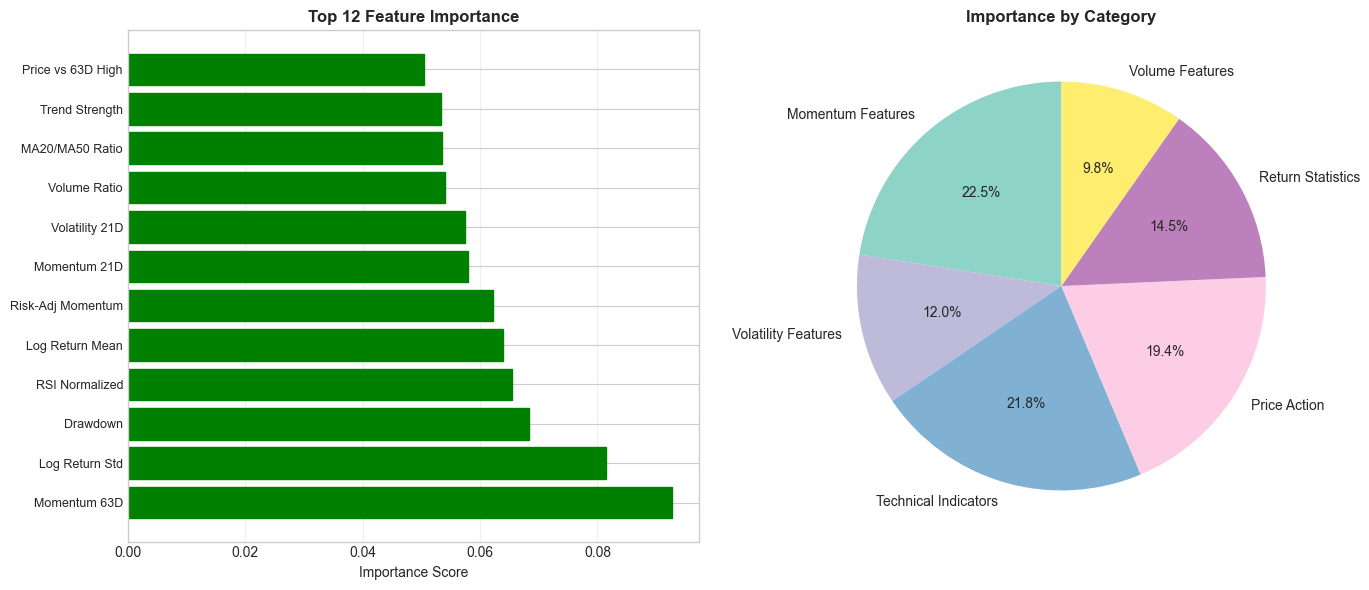


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. TOWR: 7.402%
  2. ANTM: 4.472%
  3. EXCL: 2.644%
  4. INCO: 2.353%
  5. ELSA: 2.241%
  6. BRPT: 1.349%
  7. MDKA: 1.090%
  8. KLBF: 1.078%
  9. BMRI: 1.032%
 10. MAPA: 1.031%
 11. BBRI: 0.966%
 12. ERAA: 0.722%
 13. TKIM: 0.698%
 14. AMRT: 0.693%
 15. ESSA: 0.682%

Applying filter (threshold=2.0%)...
 Only 5 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Pertambangan >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (5 stocks)
 - TOWR: Prediksi return 7.4% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 42.500, Kekuatan trend: 2.418, Momentum teradjust risiko: 2.418. Ekstrem: Drawdown tinggi
 - ANTM: Prediksi return 4.5% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 44.231, Kekuatan trend: 5.400, Momentum teradjust risiko: 5.400
 - EXCL: Prediksi return 2.6% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 53.521, Kekuatan trend: 2.091, Mo

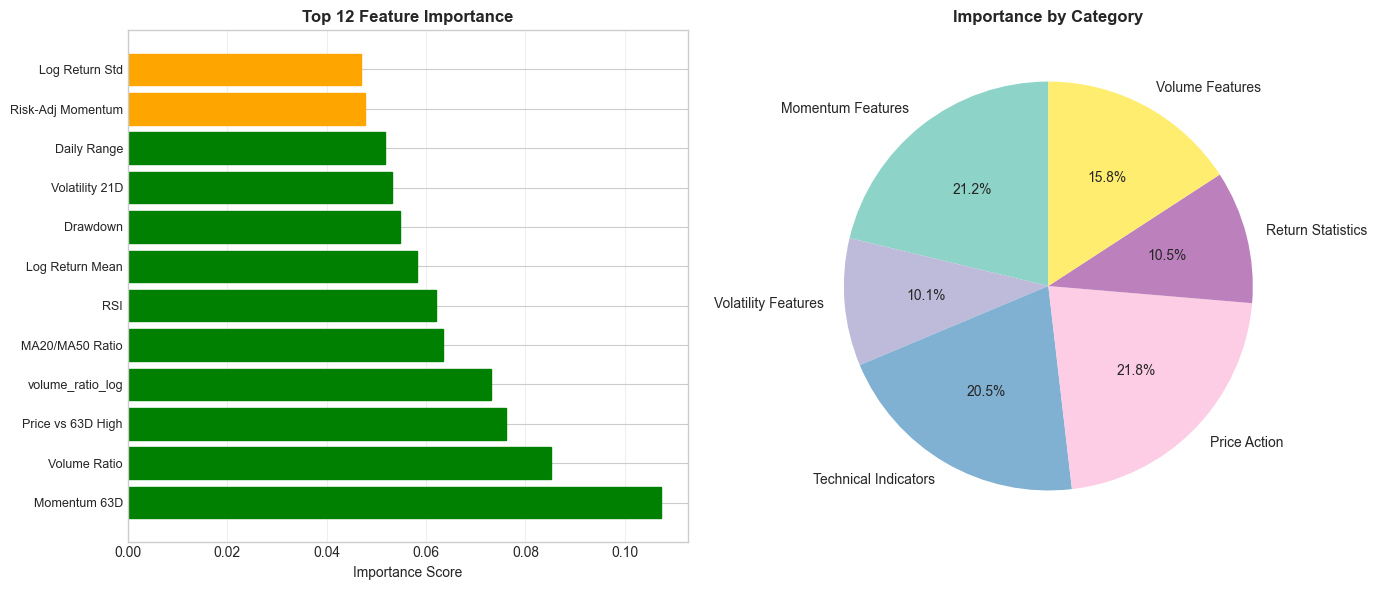


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. BRPT: 9.106%
  2. WSKT: 6.285%
  3. MEDC: 3.238%
  4. PGAS: 3.191%
  5. MAPA: 3.042%
  6. ELSA: 3.031%
  7. SMRA: 2.335%
  8. JPFA: 2.103%
  9. BBRI: 2.019%
 10. ITMG: 1.849%
 11. CTRA: 1.600%
 12. SMGR: 1.597%
 13. AKRA: 1.573%
 14. BBNI: 1.552%
 15. ESSA: 1.540%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Energi >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - BRPT: Prediksi return 9.1% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 31.765, Kekuatan trend: 6.492, Momentum teradjust risiko: -6.492. Ekstrem: Momentum 5 hari rendah, Momentum 10 hari rendah
 - WSKT: Prediksi return 6.3% (Negative Momentum, Value Play, Strong Trend). Faktor utama: RSI: 14.286, Kekuatan trend: 12.718, Momentum teradjust risiko: -12.718. Ekstrem: Momentum 5 hari rendah, Momentum 10 hari rendah
 - MEDC: Prediksi return 3.2% (Negative Momentum, High Volatilit

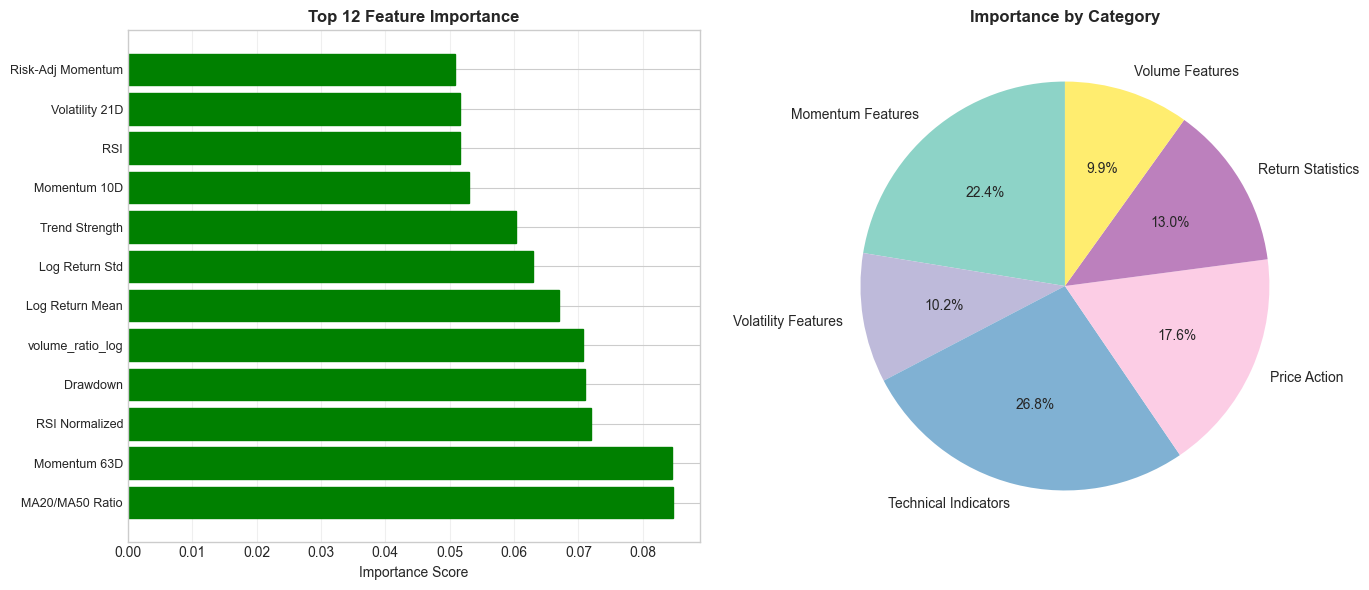


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. ANTM: 19.074%
  2. MDKA: 15.255%
  3. HRUM: 14.303%
  4. ELSA: 12.832%
  5. MEDC: 11.436%
  6. ESSA: 10.765%
  7. TKIM: 9.843%
  8. WSKT: 9.737%
  9. AKRA: 8.598%
 10. ITMG: 8.419%
 11. BBYB: 7.959%
 12. SMRA: 7.759%
 13. BRPT: 7.624%
 14. PGAS: 7.540%
 15. INTP: 7.528%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Energi >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - ANTM: Prediksi return 19.1% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 98.810, Kekuatan trend: 12.336, Momentum teradjust risiko: 12.336. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - MDKA: Prediksi return 15.3% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 84.016, Kekuatan trend: 7.883, Momentum teradjust risiko: 7.883. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - HRUM: Prediksi return 14.3% (High Momentum, Near

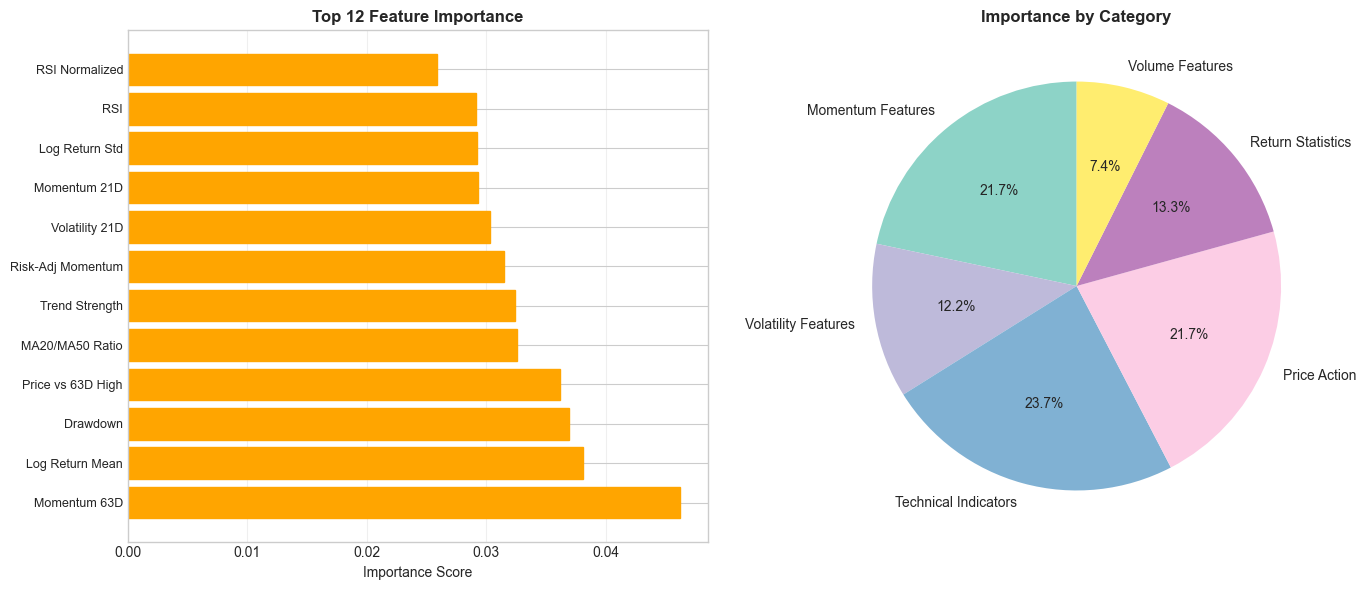


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. ESSA: 9.788%
  2. BBYB: 8.002%
  3. MAPA: 7.582%
  4. HRUM: 7.337%
  5. JPFA: 4.301%
  6. TKIM: 3.659%
  7. MEDC: 3.516%
  8. AKRA: 3.436%
  9. SMRA: 3.240%
 10. AMRT: 3.203%
 11. ANTM: 3.140%
 12. CTRA: 3.011%
 13. INKP: 2.732%
 14. PWON: 2.659%
 15. TOWR: 2.487%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Energi >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - ESSA: Prediksi return 9.8% (High Momentum, Near High, High Volatility, Strong Trend, High Volume). Faktor utama: RSI: 74.074, Rasio volume: 5.406, Kekuatan trend: 5.013. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - BBYB: Prediksi return 8.0% (High Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 22.727, Kekuatan trend: 3.466, Momentum teradjust risiko: 3.466. Ekstrem: Momentum 5 hari rendah, Momentum 10 hari rendah
 - MAPA: Prediksi return 7.6% (Negative Momentum). Faktor ut

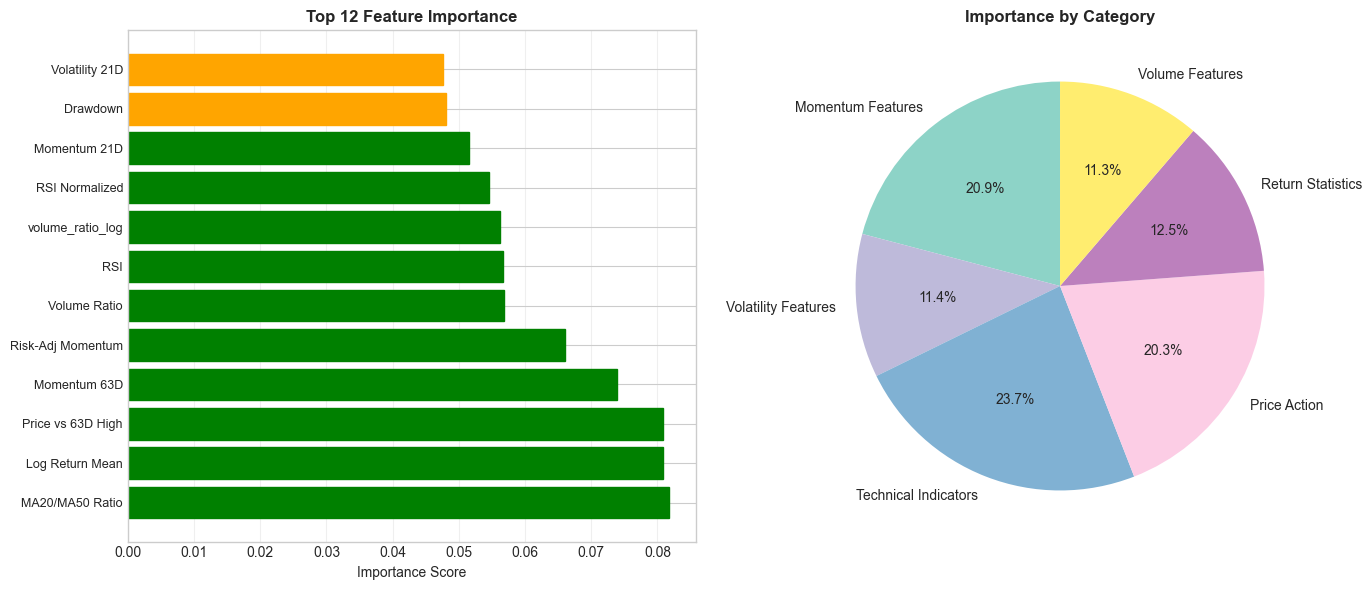


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. BBYB: 7.753%
  2. WSKT: 4.170%
  3. MDKA: 3.211%
  4. AKRA: 2.801%
  5. TKIM: 2.041%
  6. INKP: 1.983%
  7. MAPA: 1.695%
  8. ERAA: 1.627%
  9. TLKM: 1.559%
 10. EXCL: 1.544%
 11. AMRT: 1.436%
 12. PGAS: 1.405%
 13. ITMG: 1.374%
 14. TOWR: 1.237%
 15. ADRO: 1.226%

Applying filter (threshold=2.0%)...
 Only 5 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Industri >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (5 stocks)
 - BBYB: Prediksi return 7.8% (Negative Momentum, Value Play, High Volatility). Faktor utama: RSI: 50.501, Rasio MA20/MA50: 0.963, Harga vs high 63 hari: 0.683. Ekstrem: Momentum 63 hari rendah, Volatilitas tinggi
 - WSKT: Prediksi return 4.2% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 54.167, Kekuatan trend: 2.244, Momentum teradjust risiko: -2.244. Ekstrem: Harga vs high 63 hari rendah, Drawdown rendah
 - MDKA: Prediksi return 3.2% (Hi

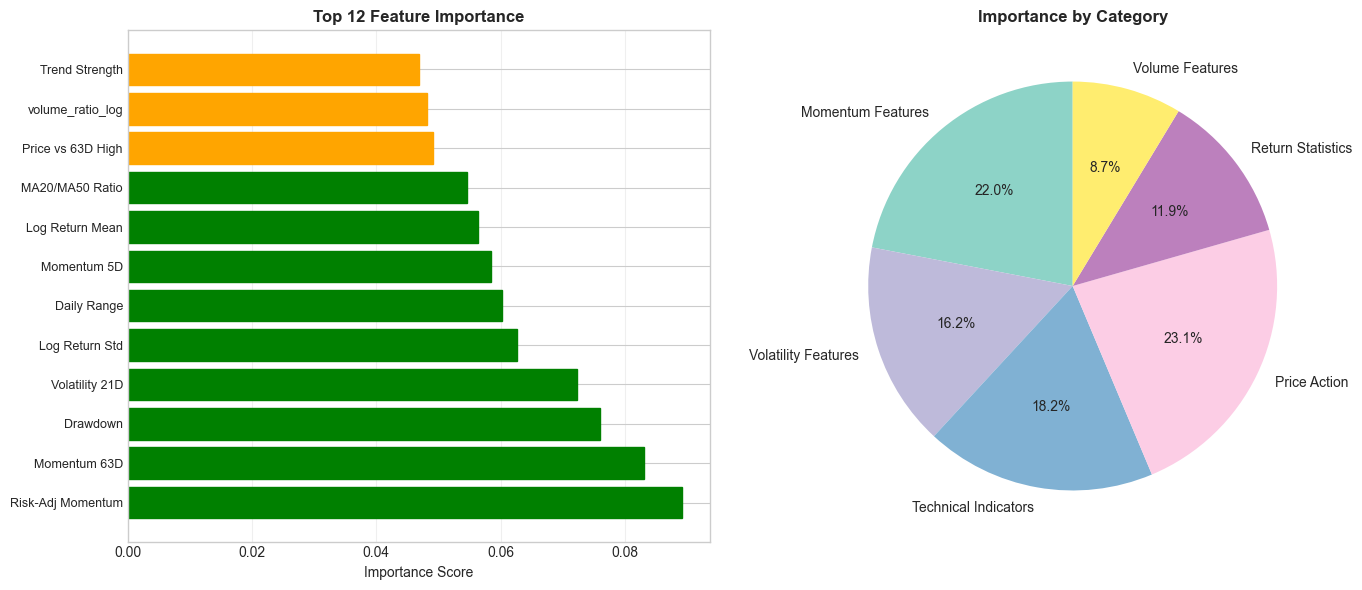


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. MEDC: 9.095%
  2. TKIM: 4.845%
  3. PGAS: 4.583%
  4. INKP: 4.218%
  5. WSKT: 3.587%
  6. MAPA: 3.324%
  7. UNVR: 3.202%
  8. INTP: 2.038%
  9. BBNI: 1.461%
 10. PTBA: 1.309%
 11. BRPT: 1.279%
 12. ASII: 1.277%
 13. AKRA: 1.195%
 14. PWON: 1.146%
 15. SMRA: 1.034%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - MEDC: Prediksi return 9.1% (Negative Momentum, Value Play, High Volatility). Faktor utama: RSI: 40.000, Rasio body candle: 1.000, Rasio MA20/MA50: 0.921. Ekstrem: Volatilitas tinggi, Kekuatan trend rendah
 - TKIM: Prediksi return 4.8% (Strong Trend). Faktor utama: RSI: 79.513, Kekuatan trend: 4.747, Momentum teradjust risiko: 4.747
 - PGAS: Prediksi return 4.6% (Strong Trend). Faktor utama: RSI: 50.000, Kekuatan trend: 2.452, Momentum teradjust risiko: 2.452. Ekstrem: Drawdown rendah
 - INKP: Prediksi return 4.

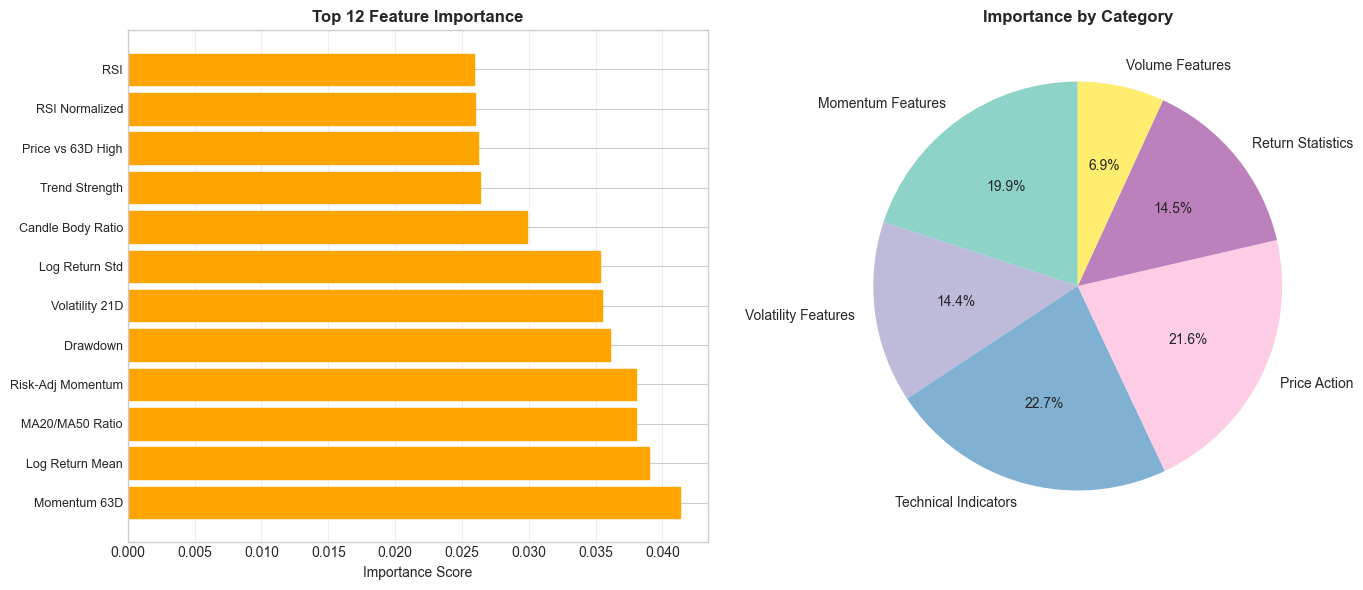


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. UNVR: 1.921%
  2. HRUM: 0.995%
  3. MDKA: 0.940%
  4. BBYB: 0.588%
  5. ADRO: 0.559%
  6. INTP: 0.157%
  7. SMGR: 0.096%
  8. INKP: -0.006%
  9. TKIM: -0.099%
 10. AKRA: -0.302%
 11. MIKA: -0.406%
 12. BRPT: -0.417%
 13. TLKM: -0.438%
 14. PWON: -0.446%
 15. PGAS: -0.449%

Applying filter (threshold=2.0%)...
 Only 0 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Energi >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (5 stocks)
 - UNVR: Prediksi return 1.9% (Neutral). Faktor utama: RSI: 43.201, Rasio body candle: 1.000, Rasio MA20/MA50: 0.997
 - HRUM: Prediksi return 1.0% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 70.952, Kekuatan trend: 5.399, Momentum teradjust risiko: 5.399. Ekstrem: Momentum 21 hari tinggi, Momentum 63 hari tinggi
 - MDKA: Prediksi return 0.9% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 67.257, Kekuatan trend: 6.724, Momen

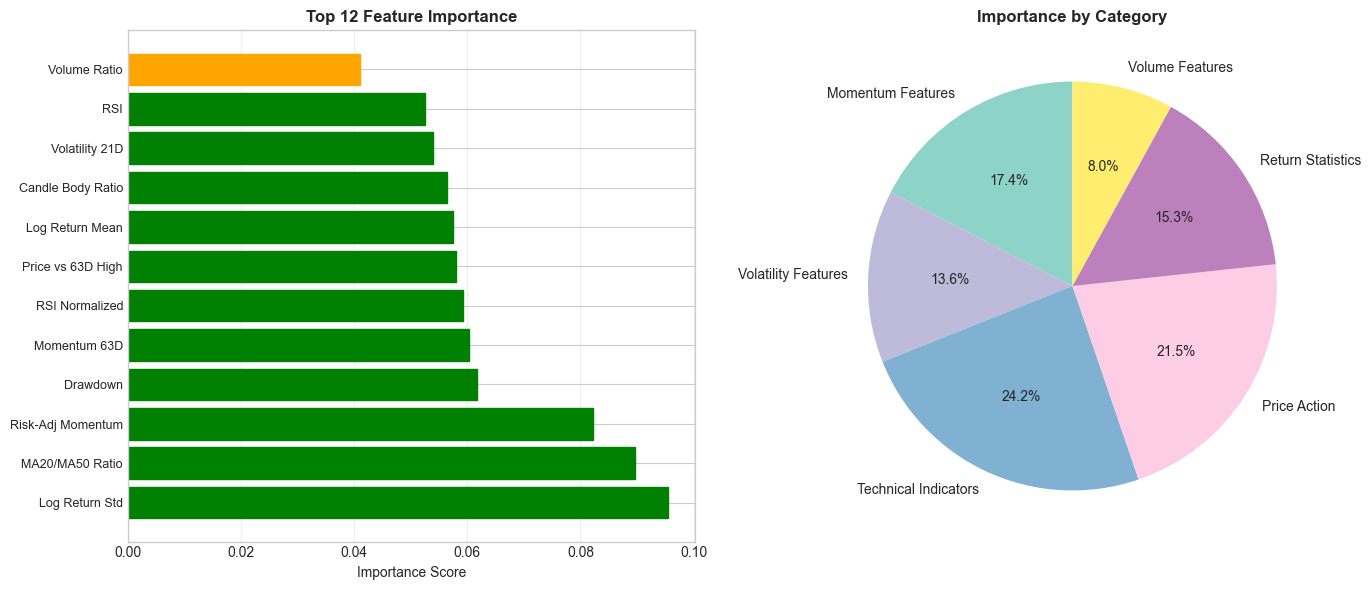


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. ESSA: 14.689%
  2. INKP: 6.778%
  3. WSKT: 6.605%
  4. TKIM: 6.135%
  5. UNVR: 5.827%
  6. EXCL: 5.512%
  7. MAPA: 5.059%
  8. SMRA: 4.958%
  9. PTBA: 4.904%
 10. PGAS: 4.743%
 11. ICBP: 4.572%
 12. SMGR: 4.487%
 13. BBYB: 4.463%
 14. ITMG: 4.374%
 15. ADRO: 4.287%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - ESSA: Prediksi return 14.7% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 69.697, Kekuatan trend: 5.769, Momentum teradjust risiko: 5.769. Ekstrem: Momentum 5 hari tinggi, Momentum 63 hari tinggi
 - INKP: Prediksi return 6.8% (High Momentum, Near High, High Volatility, Strong Trend, High Volume). Faktor utama: RSI: 63.889, Rasio volume: 3.412, Kekuatan trend: 3.117. Ekstrem: Rasio volume tinggi, volume_ratio_log tinggi
 - WSKT: Prediksi return 6.6% (Negative Momentum, Value Play

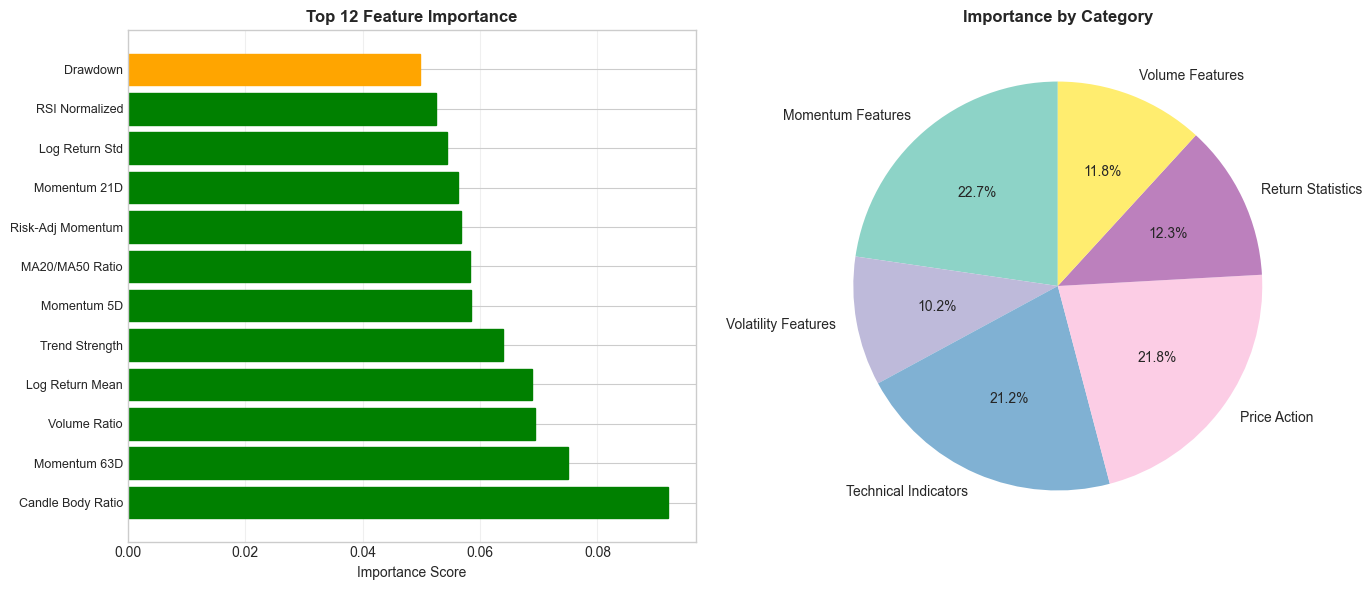


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. INKP: 8.426%
  2. BBYB: 7.533%
  3. TKIM: 7.318%
  4. MEDC: 6.735%
  5. WSKT: 6.613%
  6. INTP: 5.687%
  7. PTBA: 5.590%
  8. MAPA: 5.388%
  9. UNVR: 5.369%
 10. JPFA: 5.304%
 11. ITMG: 5.231%
 12. SMRA: 5.207%
 13. PGAS: 4.742%
 14. ICBP: 4.544%
 15. SMGR: 4.403%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - INKP: Prediksi return 8.4% (High Momentum, Near High, Strong Trend, High Volume). Faktor utama: RSI: 70.787, Kekuatan trend: 4.716, Momentum teradjust risiko: 4.716. Ekstrem: Rasio body candle rendah, Rasio volume tinggi
 - BBYB: Prediksi return 7.5% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 45.098, Kekuatan trend: 5.514, Momentum teradjust risiko: -5.514. Ekstrem: Momentum 21 hari rendah, Momentum 63 hari rendah
 - TKIM: Prediksi return 7.3% (High Momentum, Near High, S

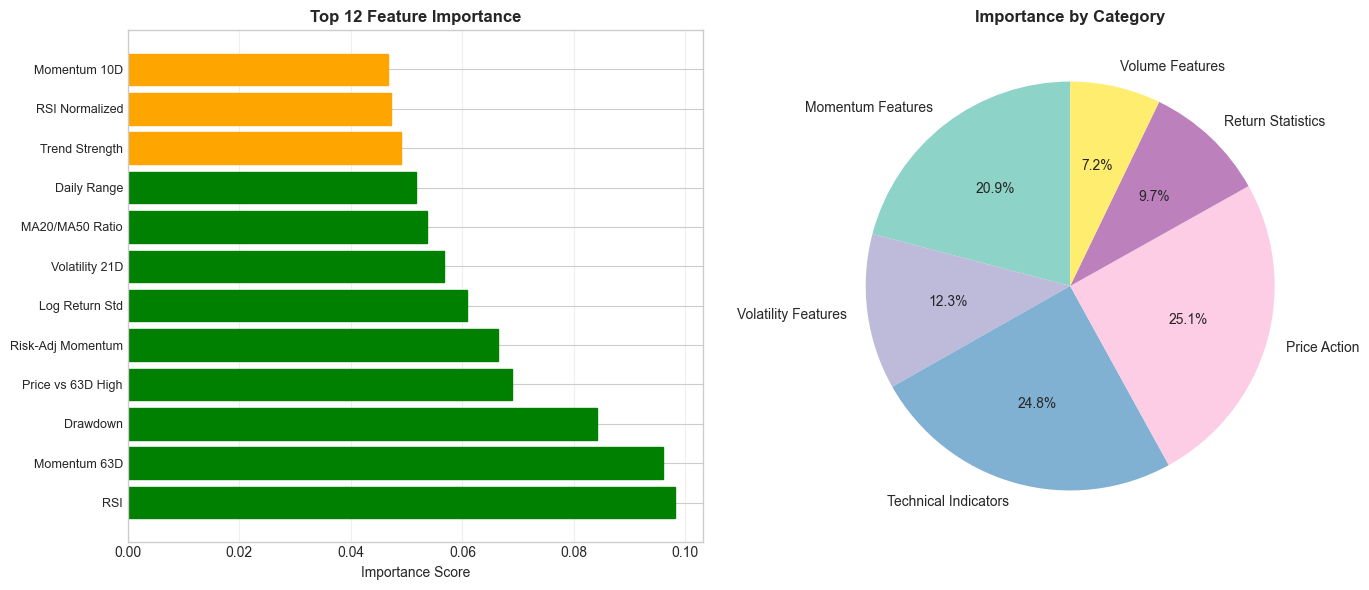


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. MEDC: 6.045%
  2. TKIM: 6.000%
  3. INKP: 4.946%
  4. UNVR: 3.676%
  5. SMGR: 3.385%
  6. WSKT: 3.197%
  7. INCO: 3.186%
  8. MAPA: 3.037%
  9. HRUM: 3.032%
 10. INTP: 2.927%
 11. BBCA: 2.223%
 12. BRPT: 2.178%
 13. SMRA: 2.113%
 14. ANTM: 1.959%
 15. JPFA: 1.911%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - MEDC: Prediksi return 6.0% (High Momentum, Near High, High Volatility, Strong Trend, High Volume). Faktor utama: RSI: 88.522, Kekuatan trend: 10.504, Momentum teradjust risiko: 10.504. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - TKIM: Prediksi return 6.0% (Near High, Strong Trend). Faktor utama: RSI: 72.000, Kekuatan trend: 5.496, Momentum teradjust risiko: 5.496. Ekstrem: Drawdown rendah
 - INKP: Prediksi return 4.9% (High Momentum, Near High, Strong Trend, High Volume). Faktor utama: RSI: 77.2

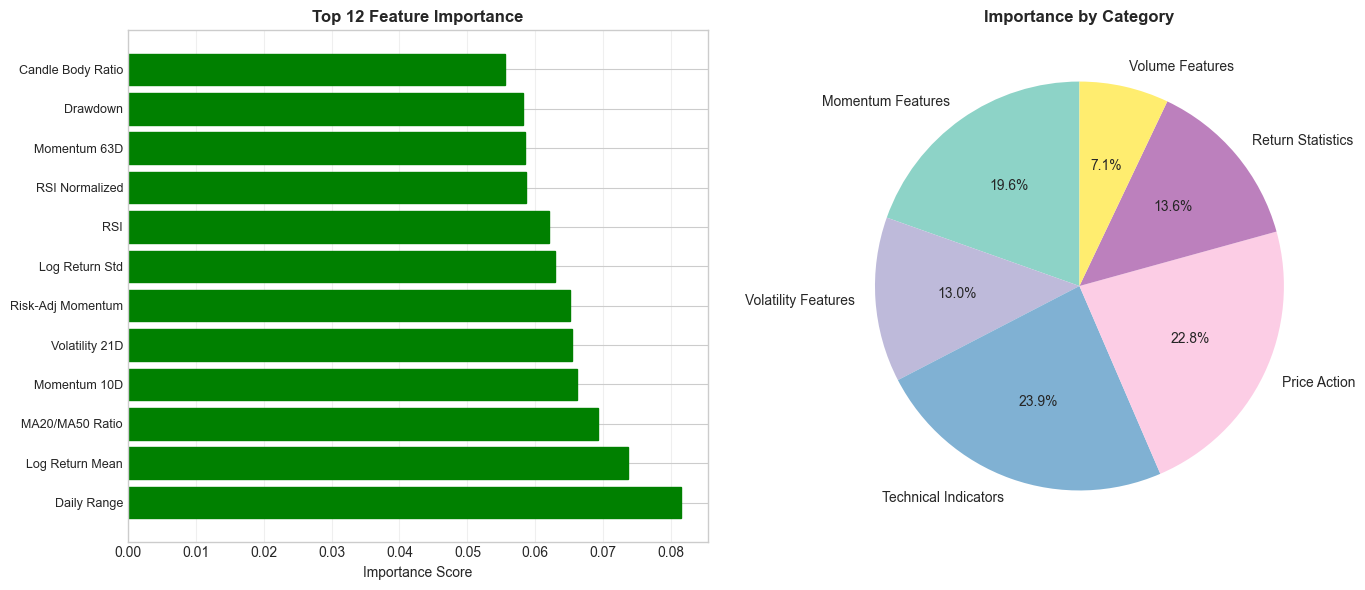


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. SMRA: 3.923%
  2. WSKT: 3.658%
  3. BBYB: 3.478%
  4. JPFA: 2.611%
  5. INTP: 2.306%
  6. INKP: 2.034%
  7. TKIM: 1.989%
  8. PWON: 1.977%
  9. UNVR: 1.936%
 10. MDKA: 1.844%
 11. CTRA: 1.749%
 12. BBCA: 1.680%
 13. BUKA: 1.554%
 14. ANTM: 1.511%
 15. KLBF: 1.475%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (5 stocks)
 - SMRA: Prediksi return 3.9% (High Momentum, Strong Trend, High Volume). Faktor utama: RSI: 73.913, Kekuatan trend: 1.578, Momentum teradjust risiko: 1.578. Ekstrem: Momentum 5 hari tinggi, RSI tinggi
 - WSKT: Prediksi return 3.7% (Negative Momentum, Strong Trend). Faktor utama: RSI: 27.273, Kekuatan trend: 3.014, Momentum teradjust risiko: -3.014. Ekstrem: Harga vs high 63 hari rendah, Drawdown rendah
 - BBYB: Prediksi return 3.5% (Negative Momentum, High Volatility). Faktor utama: RSI: 58.253, Rasio volume: 1.4

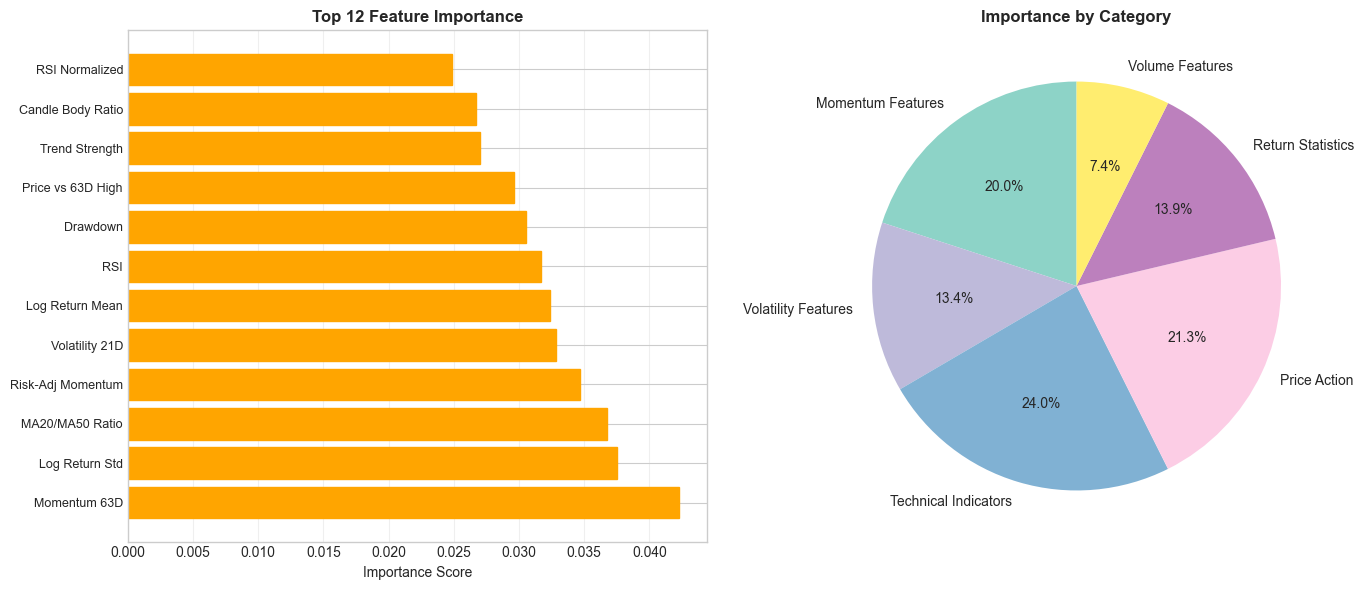


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. TKIM: 7.995%
  2. INKP: 6.660%
  3. SMRA: 6.539%
  4. JPFA: 6.087%
  5. UNVR: 6.002%
  6. MEDC: 5.984%
  7. BBYB: 5.825%
  8. PGAS: 5.570%
  9. ANTM: 5.393%
 10. WSKT: 5.021%
 11. BUKA: 4.996%
 12. PWON: 4.917%
 13. HRUM: 4.603%
 14. EXCL: 4.422%
 15. BBNI: 4.405%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:

 STOCK-SPECIFIC EXPLANATIONS (8 stocks)
 - TKIM: Prediksi return 8.0% (Negative Momentum, Strong Trend). Faktor utama: RSI: 29.730, Kekuatan trend: 1.527, Momentum teradjust risiko: -1.527
 - INKP: Prediksi return 6.7% (Negative Momentum, Strong Trend). Faktor utama: RSI: 29.412, Kekuatan trend: 6.708, Momentum teradjust risiko: -6.708. Ekstrem: Harga vs high 63 hari rendah
 - SMRA: Prediksi return 6.5% (Negative Momentum). Faktor utama: RSI: 32.000, Kekuatan trend: 1.306, Momentum teradjust risiko: -1.306
 - JPFA: Prediksi return 6.1% (Near High). Faktor utama: RSI: 40.000, Rasi

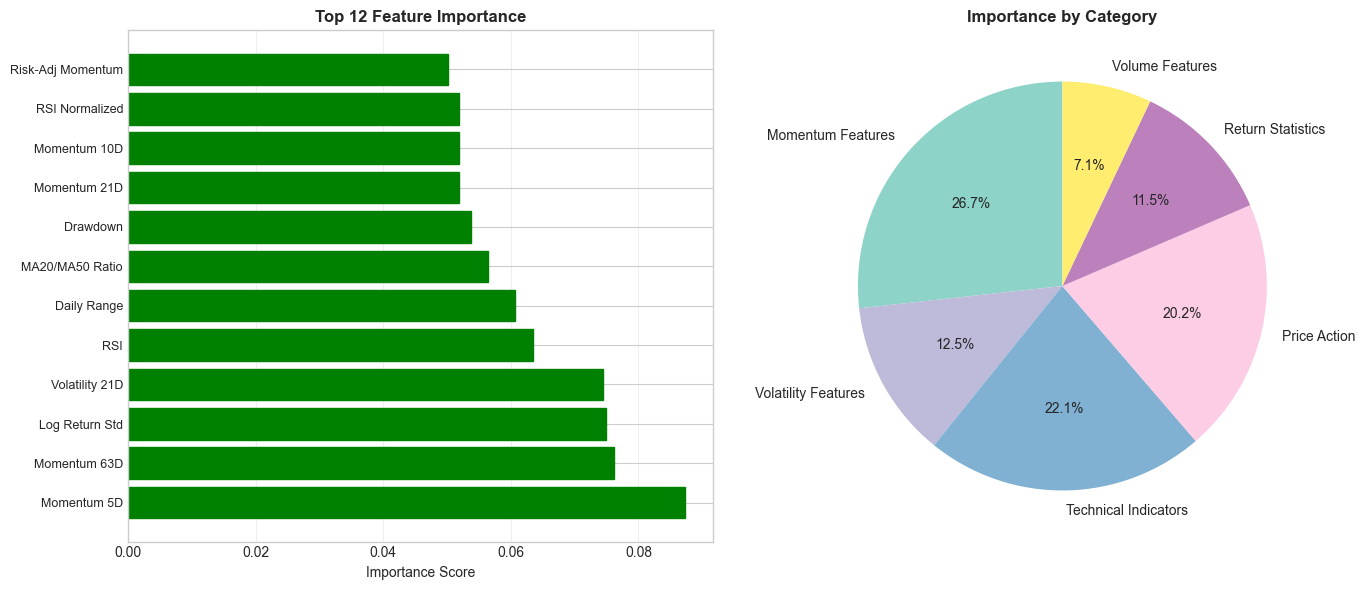


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. ESSA: 5.805%
  2. JPFA: 4.674%
  3. SMGR: 3.539%
  4. SMRA: 2.677%
  5. UNVR: 2.667%
  6. MEDC: 2.163%
  7. BBYB: 2.141%
  8. INTP: 2.081%
  9. ICBP: 2.033%
 10. INKP: 1.995%
 11. CPIN: 1.963%
 12. BUKA: 1.904%
 13. GOTO: 1.876%
 14. BBRI: 1.850%
 15. MDKA: 1.725%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - ESSA: Prediksi return 5.8% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 27.143, Kekuatan trend: 9.318, Momentum teradjust risiko: -9.318. Ekstrem: Momentum 21 hari rendah, Momentum 63 hari rendah
 - JPFA: Prediksi return 4.7% (High Momentum, Near High, Strong Trend, High Volume). Faktor utama: RSI: 78.688, Kekuatan trend: 7.348, Momentum teradjust risiko: 7.348. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - SMGR: Prediksi return 3.5% (Neutral). Faktor utama: R

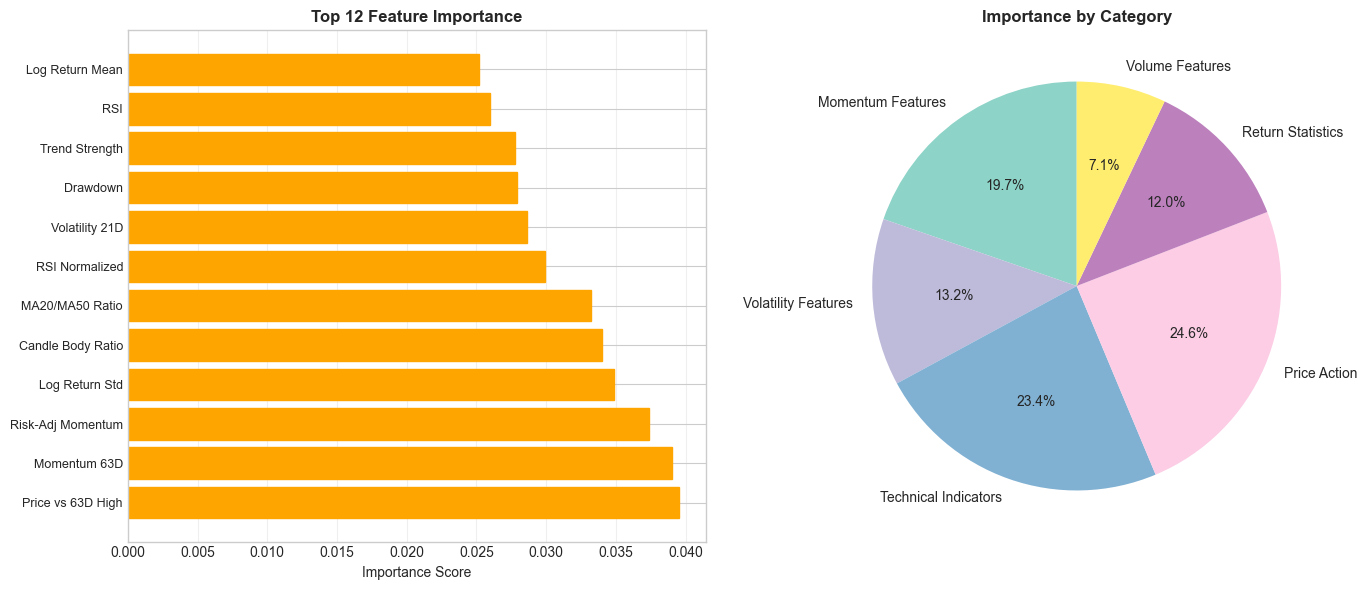


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. BBYB: 5.249%
  2. SMRA: 3.080%
  3. ERAA: 2.995%
  4. GOTO: 2.368%
  5. JPFA: 2.267%
  6. UNVR: 2.095%
  7. SMGR: 2.005%
  8. INTP: 1.968%
  9. BRPT: 1.916%
 10. WSKT: 1.868%
 11. BUKA: 1.724%
 12. PGAS: 1.500%
 13. SIDO: 1.382%
 14. CTRA: 1.169%
 15. ANTM: 0.843%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - BBYB: Prediksi return 5.2% (High Momentum, High Volatility, High Volume). Faktor utama: RSI: 64.000, Rasio volume: 3.321, volume_ratio_log: 1.463. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - SMRA: Prediksi return 3.1% (High Volatility). Faktor utama: RSI: 66.667, Rasio body candle: 1.000, Rasio MA20/MA50: 0.955
 - ERAA: Prediksi return 3.0% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor utama: RSI: 19.048, Kekuatan trend: 5.906, Momentum teradjust risiko: -5.906. Ekstrem: Momentum 10 hari rendah, M

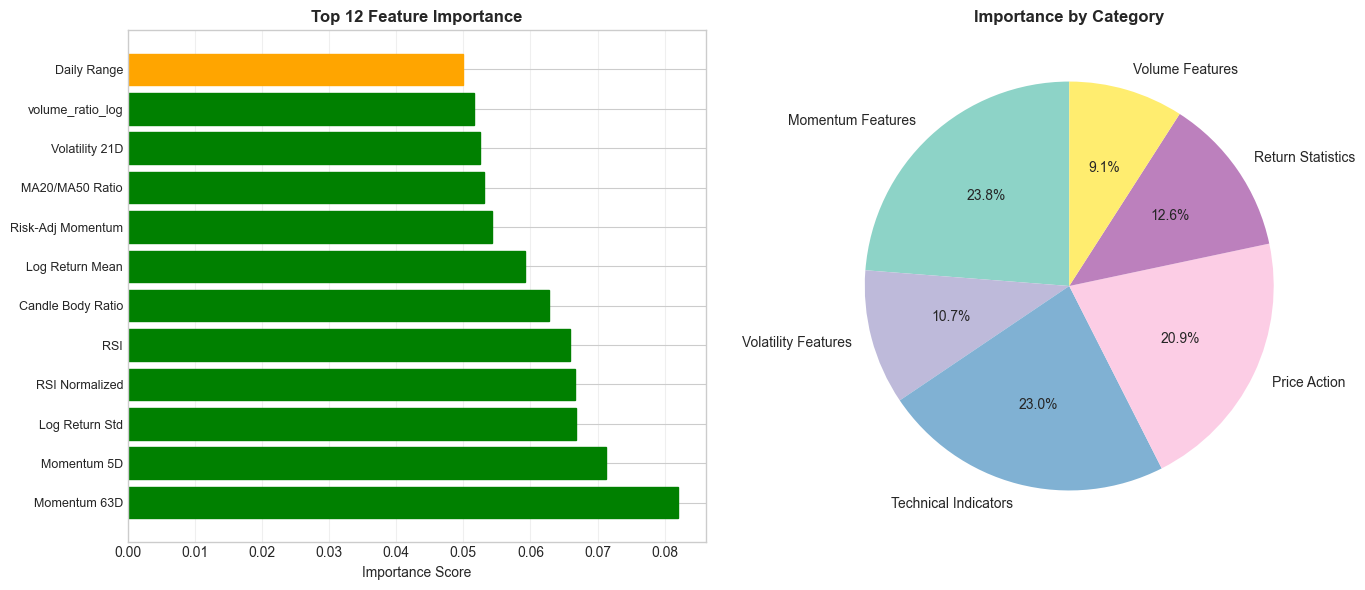


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. JPFA: 1.281%
  2. SMRA: 1.087%
  3. BUKA: 1.061%
  4. TKIM: 0.834%
  5. UNVR: 0.808%
  6. SMGR: 0.295%
  7. PWON: 0.025%
  8. PTBA: -0.109%
  9. INCO: -0.113%
 10. MIKA: -0.118%
 11. TOWR: -0.119%
 12. EXCL: -0.163%
 13. ANTM: -0.200%
 14. WSKT: -0.236%
 15. PGAS: -0.253%

Applying filter (threshold=2.0%)...
 Only 0 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Konsumer >30% (2/6)
Sector Industri >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (4 stocks)
 - JPFA: Prediksi return 1.3% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 65.790, Kekuatan trend: 2.971, Momentum teradjust risiko: 2.971. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - SMRA: Prediksi return 1.1% (Strong Trend). Faktor utama: RSI: 54.167, Kekuatan trend: 1.708, Momentum teradjust risiko: -1.708
 - BUKA: Prediksi return 1.1% (Negative Momentum, Value Play, High Volatility, Strong Trend). Faktor ut

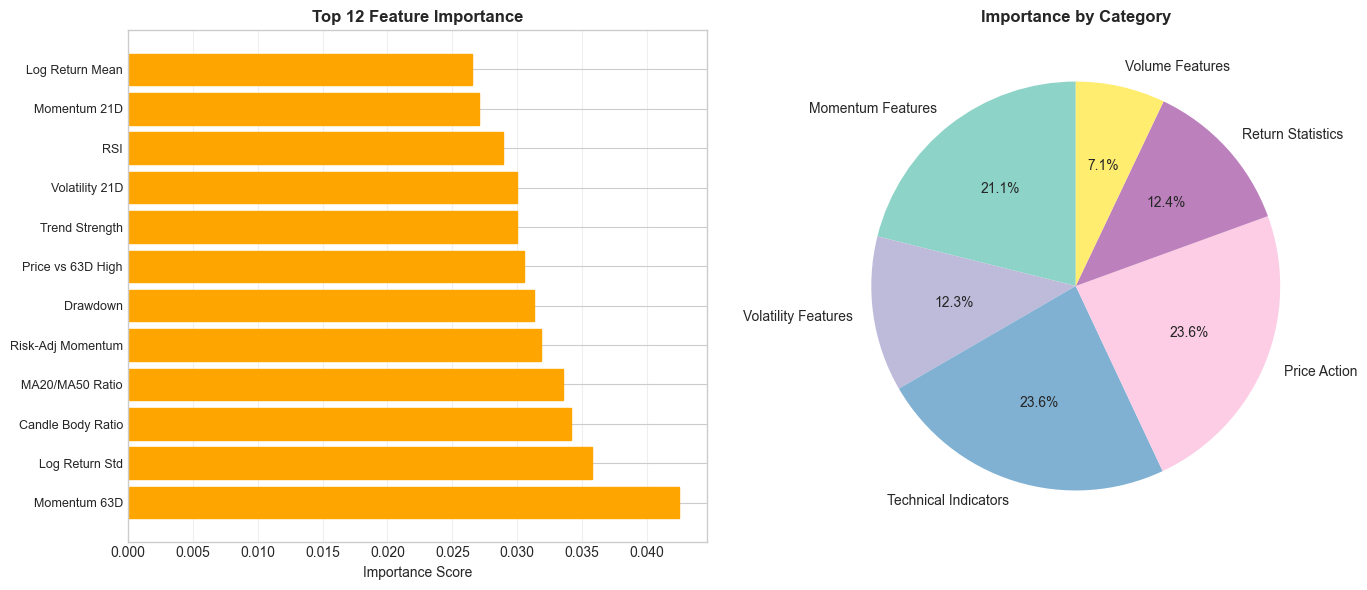


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. TOWR: 3.800%
  2. ICBP: 2.889%
  3. INTP: 2.761%
  4. PWON: 2.610%
  5. ADRO: 2.411%
  6. BBNI: 2.369%
  7. BMRI: 2.272%
  8. ANTM: 2.268%
  9. INDF: 2.253%
 10. UNTR: 2.204%
 11. ERAA: 2.158%
 12. MAPA: 2.084%
 13. KLBF: 1.995%
 14. PTBA: 1.929%
 15. CTRA: 1.812%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:

 STOCK-SPECIFIC EXPLANATIONS (8 stocks)
 - TOWR: Prediksi return 3.8% (Near High, Strong Trend, High Volume). Faktor utama: RSI: 53.571, Kekuatan trend: 4.458, Momentum teradjust risiko: 4.458. Ekstrem: Rasio MA20/MA50 tinggi
 - ICBP: Prediksi return 2.9% (Near High, Strong Trend, High Volume). Faktor utama: RSI: 65.455, Kekuatan trend: 7.155, Momentum teradjust risiko: 7.155. Ekstrem: Momentum teradjust risiko tinggi, RSI tinggi
 - INTP: Prediksi return 2.8% (Near High, Strong Trend, High Volume). Faktor utama: RSI: 31.250, Kekuatan trend: 2.720, Momentum teradjust risiko: -2.72

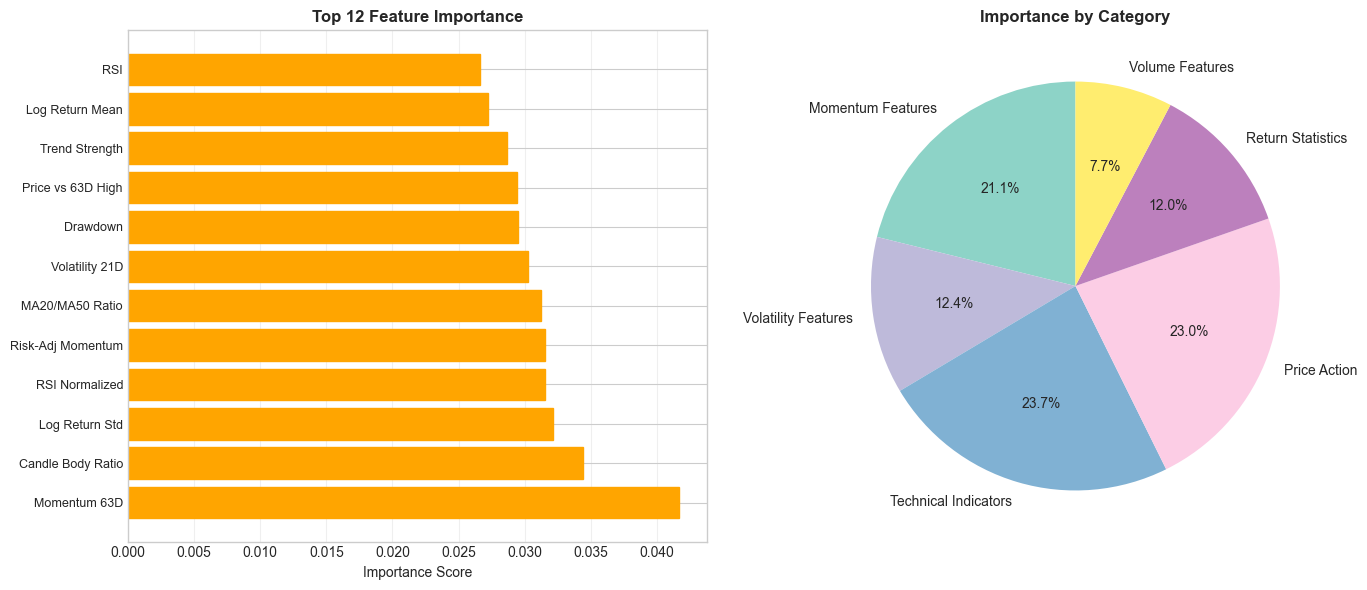


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. WSKT: 2.116%
  2. INTP: 1.892%
  3. UNVR: 1.530%
  4. ANTM: 1.364%
  5. INDF: 1.320%
  6. BBYB: 1.121%
  7. UNTR: 1.025%
  8. JPFA: 1.016%
  9. CPIN: 0.923%
 10. INKP: 0.891%
 11. AMRT: 0.871%
 12. PGAS: 0.770%
 13. MAPA: 0.720%
 14. EXCL: 0.626%
 15. MIKA: 0.522%

Applying filter (threshold=2.0%)...
 Only 1 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Konsumer >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (5 stocks)
 - WSKT: Prediksi return 2.1% (Near High). Faktor utama: Rasio volume: 1.000, RSI normalized: -1.000, Harga vs high 63 hari: 1.000. Ekstrem: Volatilitas rendah, RSI rendah
 - INTP: Prediksi return 1.9% (Near High, Strong Trend). Faktor utama: RSI: 49.296, Kekuatan trend: 2.602, Momentum teradjust risiko: 2.602
 - UNVR: Prediksi return 1.5% (Negative Momentum, Strong Trend). Faktor utama: RSI: 27.407, Kekuatan trend: 3.386, Momentum teradjust risiko: -3.386. Ekstrem: Momentum 1

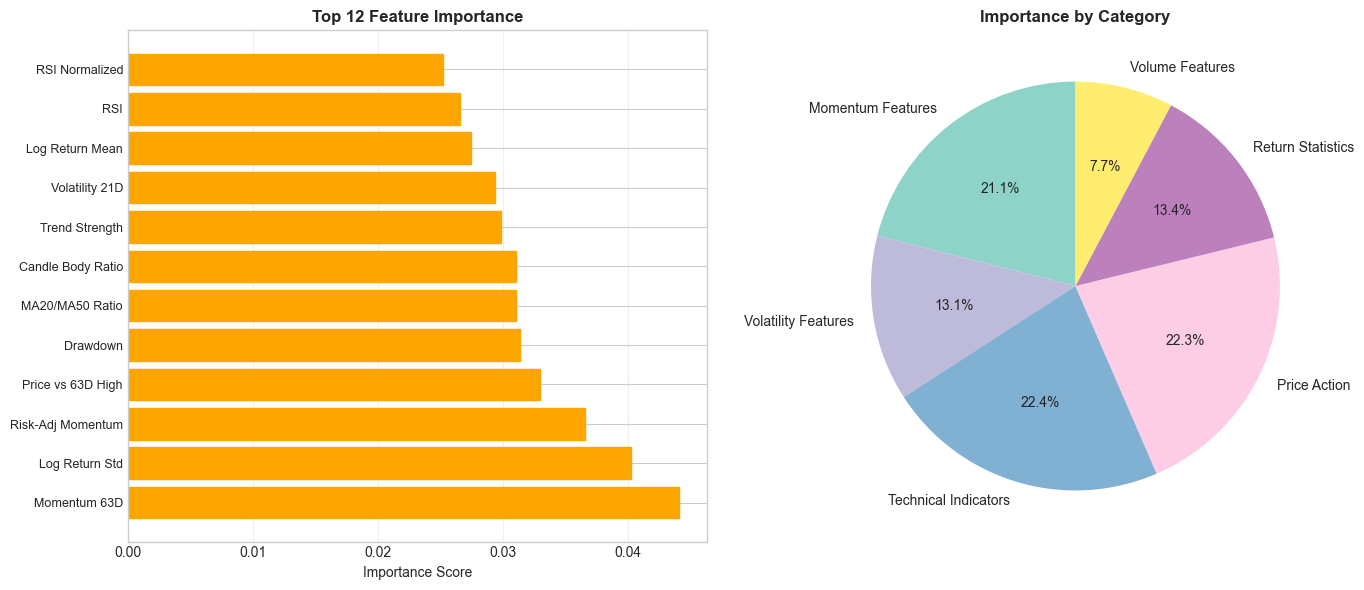


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. INCO: 6.825%
  2. BBYB: 6.636%
  3. AMMN: 5.817%
  4. HRUM: 5.085%
  5. MAPA: 5.015%
  6. BRPT: 4.789%
  7. ANTM: 4.460%
  8. ERAA: 4.199%
  9. SMGR: 3.655%
 10. UNVR: 3.638%
 11. MDKA: 3.354%
 12. AMRT: 3.215%
 13. AKRA: 2.541%
 14. INTP: 1.917%
 15. BUKA: 1.746%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Pertambangan >30% (3/8)

 STOCK-SPECIFIC EXPLANATIONS (7 stocks)
 - INCO: Prediksi return 6.8% (Value Play, High Volatility). Faktor utama: RSI: 57.246, Rasio MA20/MA50: 0.876, Drawdown: -0.707. Ekstrem: Momentum 63 hari rendah, Rasio MA20/MA50 rendah
 - BBYB: Prediksi return 6.6% (High Momentum, Near High, High Volatility, Strong Trend, High Volume). Faktor utama: RSI: 70.866, Kekuatan trend: 4.991, Momentum teradjust risiko: 4.991. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - AMMN: Prediksi return 5.8% (High Momentum, High Volatility). Faktor utama: RSI: 72

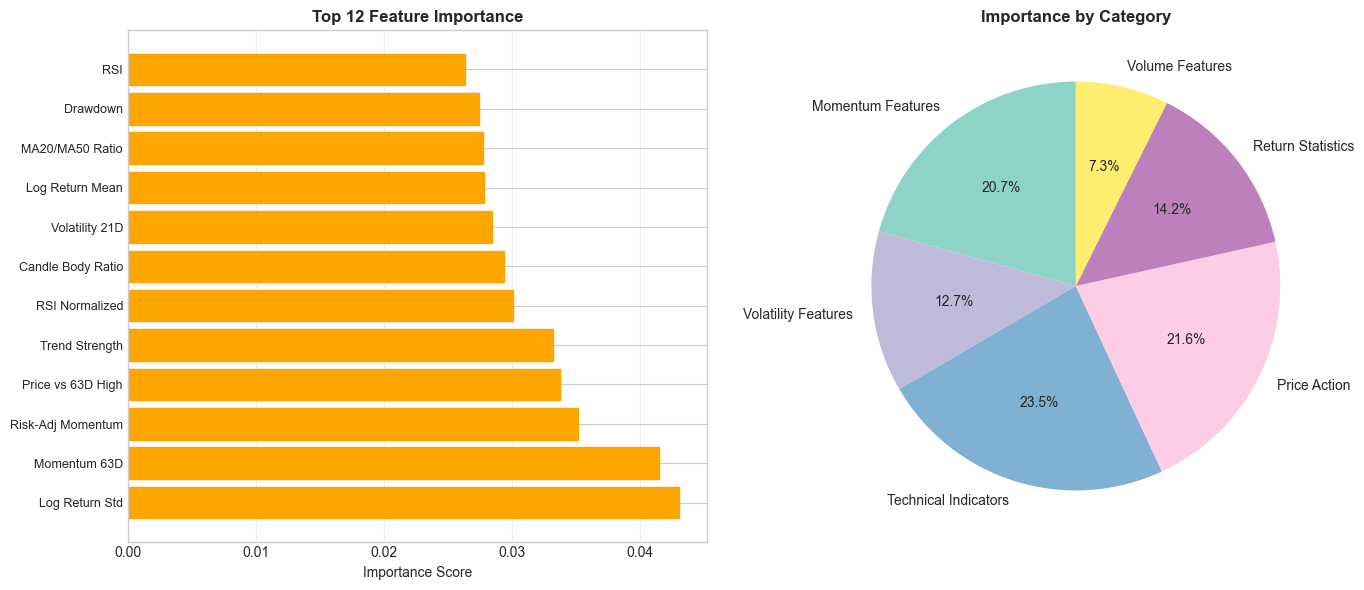


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. BRPT: 5.653%
  2. INKP: 2.970%
  3. UNTR: 2.769%
  4. TKIM: 2.669%
  5. UNVR: 2.524%
  6. BBYB: 2.068%
  7. GOTO: 1.673%
  8. TOWR: 1.659%
  9. HRUM: 1.586%
 10. BUKA: 1.559%
 11. PWON: 1.558%
 12. SMRA: 1.330%
 13. ASII: 1.246%
 14. INDF: 1.111%
 15. ADRO: 1.068%

Applying filter (threshold=2.0%)...

SECTOR DIVERSIFICATION:
Sector Industri >30% (4/6)

 STOCK-SPECIFIC EXPLANATIONS (3 stocks)
 - BRPT: Prediksi return 5.7% (High Momentum, Near High, High Volatility, Strong Trend). Faktor utama: RSI: 77.236, Kekuatan trend: 9.208, Momentum teradjust risiko: 9.208. Ekstrem: Momentum 10 hari tinggi, Momentum 21 hari tinggi
 - UNVR: Prediksi return 2.5% (High Momentum, Strong Trend). Faktor utama: RSI: 46.269, Kekuatan trend: 5.273, Momentum teradjust risiko: 5.273. Ekstrem: Drawdown rendah, Rasio body candle tinggi
 - BBYB: Prediksi return 2.1% (High Momentum, Near High, Strong Trend). Faktor utama: RSI: 7

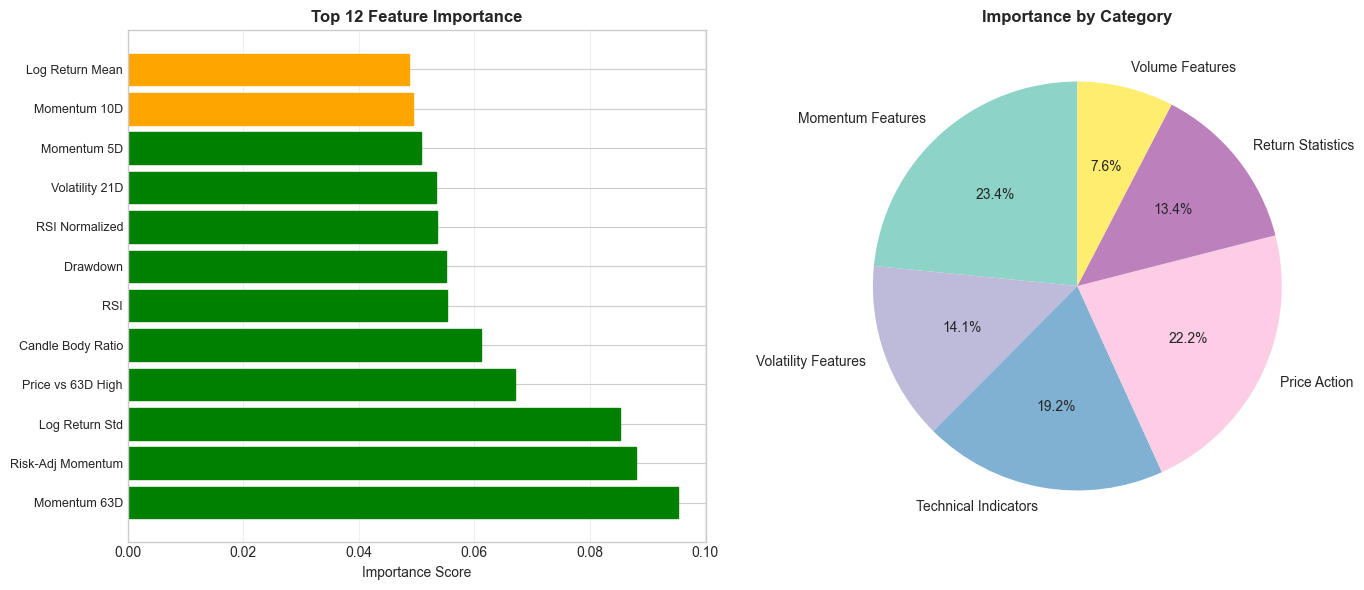


Extracting latest features...

Making predictions...

Raw predictions (top 15):
  1. BRPT: 2.415%
  2. INKP: 1.667%
  3. INTP: 1.299%
  4. JPFA: 1.151%
  5. BBYB: 1.071%
  6. UNVR: 1.013%
  7. BUKA: 0.978%
  8. TKIM: 0.951%
  9. WSKT: 0.930%
 10. GOTO: 0.904%
 11. MEDC: 0.881%
 12. SMGR: 0.606%
 13. ASII: 0.585%
 14. PWON: 0.552%
 15. MAPA: 0.548%

Applying filter (threshold=2.0%)...
 Only 1 above threshold, taking top 6

SECTOR DIVERSIFICATION:
Sector Industri >30% (3/6)
Sector Konsumer >30% (2/6)

 STOCK-SPECIFIC EXPLANATIONS (3 stocks)
 - BRPT: Prediksi return 2.4% (High Momentum, High Volatility, Strong Trend). Faktor utama: RSI: 50.704, Kekuatan trend: 5.609, Momentum teradjust risiko: 5.609. Ekstrem: Momentum 5 hari rendah, Momentum 21 hari tinggi
 - JPFA: Prediksi return 1.2% (High Momentum, Near High, Strong Trend, High Volume). Faktor utama: RSI: 84.615, Kekuatan trend: 6.077, Momentum teradjust risiko: 6.077. Ekstrem: Momentum 5 hari tinggi, Momentum 10 hari tinggi
 - BBYB: 

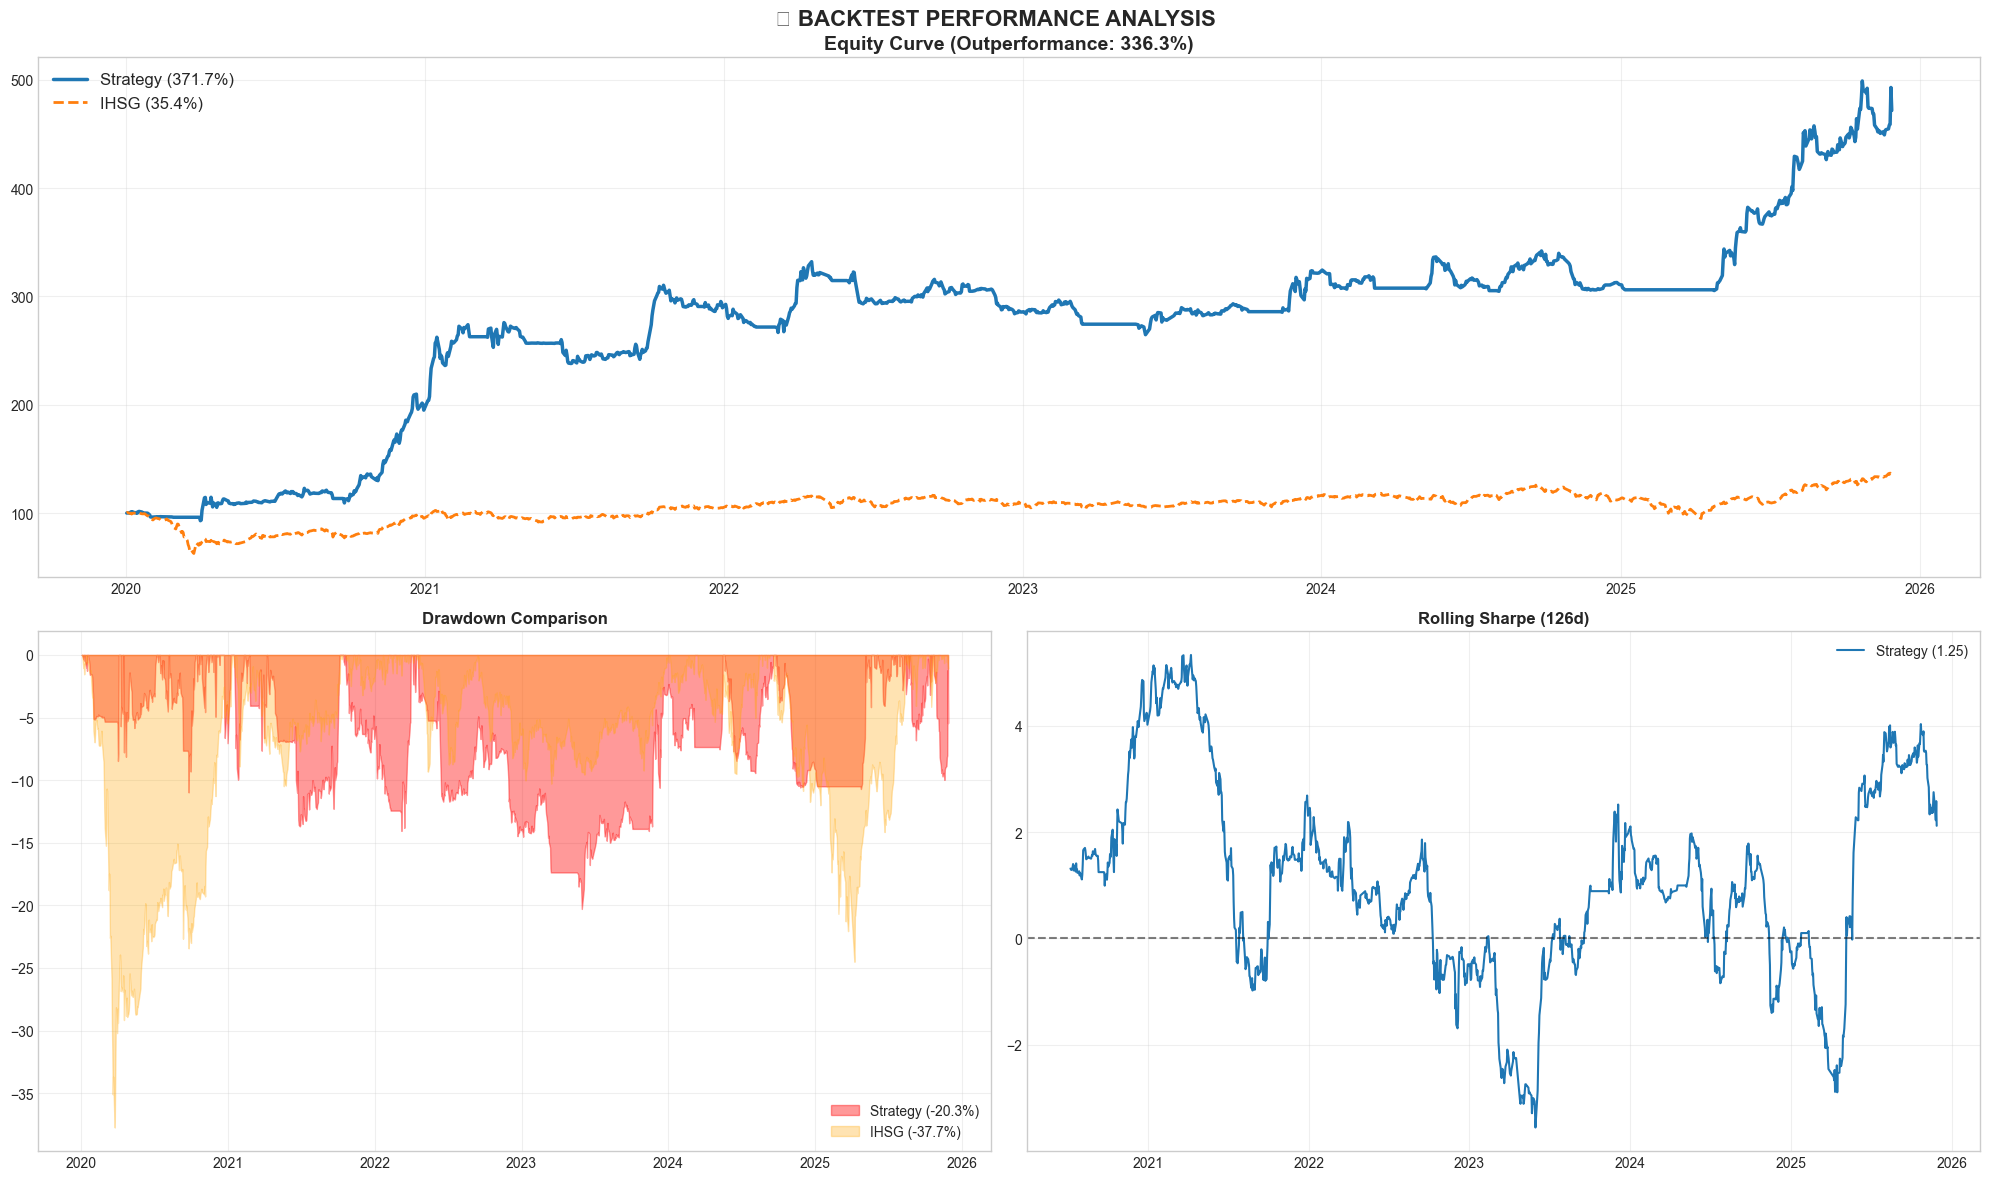


BACKTEST COMPLETED
Final Portfolio Value: Rp 470,746,663
Initial Investment: Rp 99,800,407
Total Gain: Rp 370,946,257


In [34]:
# Run backtest
print("\n" + "="*60)
print("STARTING BACKTEST")
print("="*60)

results = recommender.run_backtest(
    BACKTEST_START,
    BACKTEST_STOP,
    freq=REBAL_FREQ
)

print("\nBACKTEST COMPLETED")
print(f"Final Portfolio Value: Rp {results.iloc[-1]:,.0f}")
print(f"Initial Investment: Rp {results.iloc[0]:,.0f}")
print(f"Total Gain: Rp {results.iloc[-1] - results.iloc[0]:,.0f}")

## Cell 18: Display XAI Insights

In [35]:
# Print comprehensive XAI summary
recommender.print_xai_summary()


XAI SUMMARY ACROSS REBALANCES

FEATURE CATEGORY ANALYSIS (AVERAGE):
------------------------------------------------------------------------------------------
Category                  Contribution (%)          Top Indicators
------------------------------------------------------------------------------------------
Technical Indicators      22.7%                     MA20/MA50 Ratio, RSI
Price Action              21.8%                     Drawdown, Price vs 63D High
Momentum Features         21.6%                     Momentum 63D, Momentum 21D
Return Statistics         12.8%                     Log Return Std, Log Return Mean
Volatility Features       12.3%                     Risk-Adj Momentum, Volatility 21D
Volume Features           8.8%                      volume_ratio_log, Volume Ratio

MOST COMMON STOCK CATEGORIES:
 - Strong Trend: 106 selections (28.3%)
 - High Volatility: 61 selections (16.3%)
 - Near High: 60 selections (16.0%)
 - High Momentum: 55 selections (14.7%)
 - Negat

## Cell 19: Export Results (Optional)

In [36]:
# Export results to CSV
results_df = results.to_frame('Portfolio Value')
results_df['Return %'] = results_df['Portfolio Value'].pct_change() * 100
results_df['Cumulative Return %'] = ((results_df['Portfolio Value'] / results_df['Portfolio Value'].iloc[0]) - 1) * 100

# Save to CSV
results_df.to_csv('backtest_results.csv')
print("Results exported to 'backtest_results.csv'")

# Display summary statistics
print("\nSUMMARY STATISTICS:")
print("-" * 50)
print(results_df.describe())

Results exported to 'backtest_results.csv'

SUMMARY STATISTICS:
--------------------------------------------------
       Portfolio Value     Return %  Cumulative Return %
count     1.427000e+03  1426.000000          1427.000000
mean      2.747166e+08     0.116814           175.266053
std       8.367879e+07     1.272017            83.846145
min       9.274649e+07    -5.694643            -7.068020
25%       2.564957e+08    -0.317336           157.008676
50%       2.902863e+08     0.000000           190.866871
75%       3.098510e+08     0.377894           210.470722
max       4.978583e+08    11.224770           398.854005


---

## 📝 Notes

### Required Data Files:
- `all_data.csv` - Historical OHLCV data for LQ45 stocks
- `IHSG.csv` - IHSG benchmark data

### Key Features:
1. **Hybrid ML Model**: LSTM + XGBoost ensemble
2. **Technical Features**: 18+ indicators from OHLCV data
3. **XAI**: Feature importance + stock-specific explanations
4. **Risk Management**: Dynamic stop-loss, sector diversification
5. **Portfolio Optimization**: Sharpe ratio maximization

### Performance Metrics:
- Total/Annual Return
- Sharpe Ratio
- Maximum Drawdown
- Alpha & Beta vs IHSG
- Win Rate

### Customization:
Adjust parameters in **Cell 2** to modify:
- Prediction horizon
- Rebalance frequency
- Portfolio constraints
- Risk management rules